# UniRemington - Cali<br>Facultad de Ingeniería - Línea de Énfasis III: Ciencia de Datos y Machine Learning<br>(ↄ) Diego Fernando Marin, 2026-2

## Datos del Estudiante

**Código**: <br>
**Nombre**: Diego Fernando Benitez Camacho  
**Correo**: diego.benitez.9045@miremington.edu.co

# Taller #2 - Titanic

## 0. Introducción

### ¿Qué vas a hacer en este taller?

Vas a realizar un **análisis exploratorio de datos (EDA) completo** sobre el dataset del Titanic: explorarás los datos, los limpiarás, los transformarás, los visualizarás y, sobre todo, los **interrogarás** para entender qué características de los pasajeros aumentaron o disminuyeron sus probabilidades de sobrevivir. Este taller es la continuación del Taller #1 (Encuesta de TV): allí practicaste con **Pandas** y **Matplotlib**; aquí sumas **Seaborn** (gráficos estadísticos), **NumPy** y una primera prueba de hipótesis con **SciPy**.


### Alcance

Al terminar serás capaz de:

1. Inspeccionar un dataset nuevo y **diagnosticar datos faltantes** con tablas y mapas de calor.
2. Construir **variables nuevas** (*feature engineering*): `Person`, `Alone`, `TCabin`, `TTitulo`.
3. Elegir y construir el gráfico adecuado con Seaborn (conteo, KDE, puntos, regresión, cajas, histogramas).
4. Aplicar y **justificar** estrategias de imputación (moda, promedio por grupo) y reconocer el sesgo que introducen.
5. Codificar variables categóricas como numéricas y leer una **matriz de correlación** con sentido crítico.
6. Distinguir entre **descripción**, **asociación** y **causalidad**, y comunicar con honestidad las limitaciones de tu análisis.


Tu análisis es exitoso si puedes:

- ✅ Explicar cada decisión tomada durante la limpieza de datos.
- ✅ Justificar tus visualizaciones con argumentos claros.
- ✅ Identificar patrones no obvios en los datos.
- ✅ Reconocer las limitaciones de tu análisis.
- ✅ Comunicar tus hallazgos a una audiencia no técnica.
- ✅ Formular hipótesis comprobables a partir de tus observaciones.

## 1. Contexto del problema

Imagina que eres analista de datos en una **empresa de seguros** que investiga patrones históricos de supervivencia en desastres marítimos. La gerencia quiere saber, a partir del caso del Titanic (1912), **qué características de una persona aumentaron o disminuyeron su probabilidad de sobrevivir**, para alimentar modelos de riesgo y protocolos de evacuación.

> **Pregunta central:** ¿Qué factores tuvieron más influencia sobre la supervivencia de los pasajeros del Titanic?

**¿Por qué EDA y no directamente un modelo?** Porque antes de predecir hay que *entender*. Un análisis exploratorio revela errores y vacíos en los datos, genera hipótesis y evita construir modelos sobre supuestos falsos. Además, en este dataset **faltan muchos datos** (edad, cabina) y la forma en que los rellenes **cambia las conclusiones**: ese es el corazón del taller.



### Diccionario de datos

| Variable | Descripción | Tipo esperado |
|---|---|---|
| `PassengerId` | Identificador del pasajero | entero |
| `Survived` | 0 = no sobrevivió, 1 = sobrevivió | entero (categórica binaria) |
| `Pclass` | Clase del tiquete: 1 = alta, 2 = media, 3 = baja | entero (categórica ordinal) |
| `Name` | Nombre completo (incluye el título: Mr, Mrs, Miss…) | texto |
| `Sex` | `male` / `female` | categórica |
| `Age` | Edad en años | decimal (con faltantes) |
| `SibSp` | N.º de hermanos/cónyuge a bordo | entero |
| `Parch` | N.º de padres/hijos a bordo | entero |
| `Ticket` | Número de tiquete | texto |
| `Fare` | Tarifa pagada | decimal |
| `Cabin` | Cabina (la letra indica la cubierta) | texto (muchos faltantes) |
| `Embarked` | Puerto de embarque: C = Cherbourg, Q = Queenstown, S = Southampton | categórica |


## 2. Preparación del entorno

Esta celda ya está completa: es el **ejemplo resuelto** que te muestra el estilo de las siguientes. Ejecútala y lee cada línea.


In [ ]:
# 1) Importamos las librerías con sus alias convencionales
import pandas as pd                 # tablas (DataFrame)
import numpy as np                  # cálculo numérico y condiciones vectorizadas
import matplotlib.pyplot as plt     # gráficos base (Seaborn se apoya en él)
import seaborn as sns               # gráficos estadísticos de alto nivel
from scipy import stats             # pruebas estadísticas (la usaremos en la Parte 6)

In [ ]:
# 2) Estilo global: todos los gráficos heredan esta configuración
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (8, 5)   # tamaño por defecto (ancho, alto) en pulgadas
plt.rcParams['axes.titlesize'] = 13

**Nota**: el *dataset* contiene datos de quiénes sobrevivieron, quiénes no sobrevivieron, y quiénes no se sabe. Solo vamos a tener en cuenta los 2 primeros grupos, el 3er grupo lo usamos en el Taller #3.

In [ ]:
# 3) Cargamos los datos directamente desde la URL
df = pd.read_csv('https://paste.c-net.org/MarvelJinxed', nrows=891)

> **Teoría — ¿por qué varias librerías?** Cada una resuelve un problema distinto: Pandas organiza y transforma tablas; NumPy ofrece operaciones numéricas rápidas; Matplotlib dibuja; Seaborn dibuja gráficos *estadísticos* con muy pocas líneas (agrupa, calcula intervalos de confianza, aplica temas); SciPy contiene pruebas estadísticas. Se combinan porque se construyeron para ser compatibles entre sí.

> **Tip — si algo sale mal al cargar.** Si obtienes **una sola columna** con todo pegado, el separador no es la coma (en el Taller #1 era `|`). Prueba `pd.read_csv(url, sep='|')` o deja que Pandas lo adivine con `pd.read_csv(url, sep=None, engine='python')`. Si la descarga directa falla, descarga el archivo y cárgalo desde disco.

> **Tip — copia de seguridad.** Muchas transformaciones de este taller **modifican `df`**. Si te equivocas y quieres volver al inicio, vuelve a ejecutar la celda de carga.


## Parte 1 — Primer contacto con los datos (Pasos 1–5)

> **Teoría.** Antes de graficar nada, un analista responde cuatro preguntas: *¿cuánto hay?* (dimensiones), *¿de qué tipo es cada columna?* (tipos), *¿cómo se ve?* (muestra) y *¿qué falta?* (nulos). Los datos faltantes no son un detalle: **pueden sesgar todas tus conclusiones**.


### Paso 1. ¿Cuántos pasajeros (filas) y variables (columnas) hay?

**Lógica:** `shape` devuelve una tupla `(filas, columnas)`.


In [ ]:
# Obtén las dimensiones del DataFrame.
# Pista: shape es un ATRIBUTO (no lleva paréntesis).
df.shape


(891, 12)

### Paso 2. ¿Cuáles son las variables, sus nombres y tipos?

**Lógica:** `info()` muestra nombre, **cantidad de valores no nulos** y tipo (`dtype`) de cada columna. Compara el número de no nulos con el total de filas: ahí se descubren los datos faltantes.



In [ ]:
# Muestra el resumen estructural del DataFrame.
# Pista: info() es un MÉTODO (lleva paréntesis) e imprime directamente.

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


> En Pandas 3.x las columnas de texto se muestran como `str`; en versiones anteriores, como `object`. Son equivalentes para este taller.


### Paso 3. Muestra las primeras 10 filas


In [ ]:
# Muestra las 10 primeras filas.
# Pista: head(n) recibe el número de filas.
df.head(10)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


### Paso 4. Estadísticas descriptivas

**Lógica:** `describe()` resume las columnas **numéricas** (conteo, media, desviación, mínimo, cuartiles, máximo). Para las de texto hay que pedirlo aparte.


In [ ]:
# 1. Estadísticas descriptivas de las columnas numéricas.
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [ ]:
# 2. Estadísticas de las columnas NO numéricas.
#    Pista: df.select_dtypes(exclude='number').describe()
#    (mira 'unique' y 'top': ¿cuántos nombres, tiquetes y cabinas distintos hay?)
df.select_dtypes(exclude='number').describe()

,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Braund, Mr. Owen Harris",male,347082,G6,S
freq,1,577,7,4,644


### Paso 5. Identificar datos faltantes (con tabla y con mapa de calor)

**Lógica:** `df.isnull()` devuelve una tabla de `True/False` (True = falta el dato). Sumarla da el conteo por columna. Un **heatmap** de esa tabla muestra *dónde* faltan y si hay patrones (por ejemplo, filas a las que les faltan varias cosas a la vez).



In [ ]:
# 1. Cuenta los nulos por columna con isnull().sum().
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


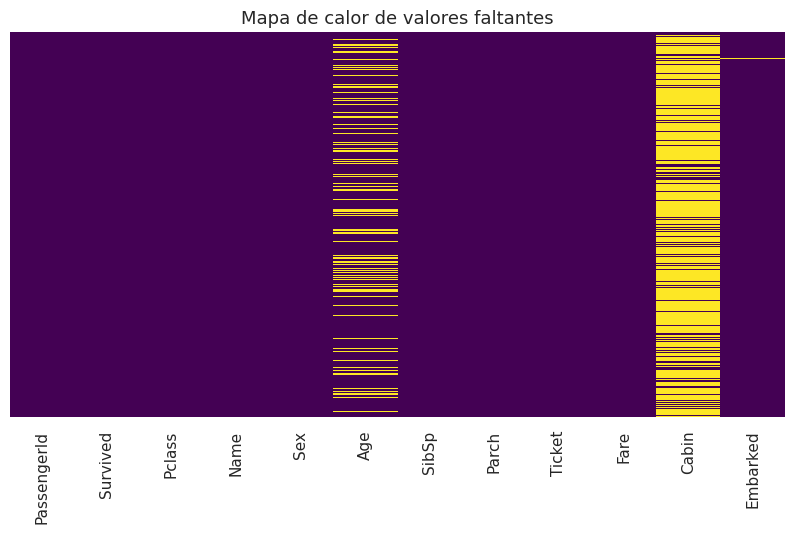

In [ ]:
# 2. Dibuja el mapa de calor de df.isnull():
#    sns.heatmap(..., cbar=False, yticklabels=False, cmap='viridis')

plt.figure(figsize=(10, 5))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap='viridis')
plt.title('Mapa de calor de valores faltantes')
plt.show()

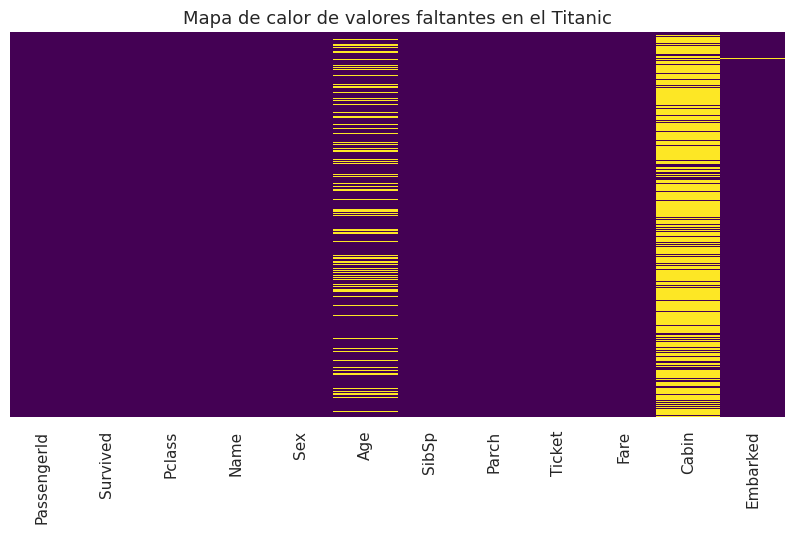

In [ ]:
# 3. Añade un título con plt.title(...) y cierra con plt.show().
plt.figure(figsize=(10, 5))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap='viridis')
plt.title('Mapa de calor de valores faltantes en el Titanic')
plt.show()


### Evaluación — Parte 1

- **E1.1 (conceptual).** ¿Cuántos pasajeros hay en total? ¿Qué columnas son numéricas y cuáles categóricas? Atención: `Survived` y `Pclass` aparecen como números, pero ¿se comportan como números (¿tiene sentido promediar `Pclass`?)


Hay 891 pasajeros. Survived y Pclass están almacenadas como números enteros, pero son categóricas: Survived es binaria (0/1) y Pclass es ordinal (1, 2, 3). No tiene sentido promediar Pclass porque sus valores son códigos de categoría, no cantidades.”

- **E1.2 (conceptual).** ¿Qué problemas "obvios" observas en los datos (columnas inútiles para el análisis, tipos extraños, faltantes)?


Las columnas PassengerId, Name, Ticket y Cabin aportan poco tal como están (identificadores o texto libre); de ellas se pueden derivar variables útiles, como el título del nombre y la letra de la cubierta. Survived y Pclass están como enteros, pero son categóricas. Hay datos faltantes importantes en Cabin (77 %), Age (20 %) y Embarked (2 casos), y Fare presenta valores extremos y tarifas de cero.

- **E1.3 (código).** Calcula el **porcentaje** de datos faltantes por columna, ordenado de mayor a menor.


In [ ]:
# Reto E1.3 — Pista: isnull().mean() devuelve la proporción de nulos por columna;
# multiplica por 100, redondea con round(1) y ordena con sort_values(ascending=False).

porcentaje_nulos = (df.isnull().mean() * 100).round(1).sort_values(ascending=False)
print(porcentaje_nulos)

Cabin          77.1
Age            19.9
Embarked        0.2
PassengerId     0.0
Name            0.0
Pclass          0.0
Survived        0.0
Sex             0.0
Parch           0.0
SibSp           0.0
Fare            0.0
Ticket          0.0
dtype: float64


- **E1.4 (conceptual).** ¿Qué columnas tienen más datos faltantes? ¿Podrían sesgar el análisis? Piensa: ¿los faltantes parecen "al azar" o tienen una causa?


Columnas con más faltantes
Cabin: 77.1 % (687 de 891)
Age: 19.9 % (177 de 891)
Embarked: 0.2 % (2 casos) Las columnas con más faltantes son Cabin (77 %) y Age (20 %). Los faltantes no son aleatorios: dependen de la clase del pasajero y del sexo, grupos que además difieren en supervivencia. Eliminar filas o imputar con un valor global sesgaría el análisis hacia primera clase; por eso conviene imputar por grupos y tratar la ausencia de Cabin como una variable informativa.

- **E1.5 (conceptual — reflexión).** ¿Por qué usamos varias bibliotecas en lugar de una sola? Da un ejemplo de tarea para cada una.


Se usan varias bibliotecas porque cada una se especializa en una tarea: pandas maneja y limpia los datos tabulares, NumPy hace cálculo numérico eficiente, matplotlib y seaborn crean visualizaciones, y scikit-learn construye modelos predictivos. Combinarlas es más flexible y eficiente que depender de una sola herramienta que haga todo de forma mediocre.

## Parte 2 — Conociendo a los pasajeros (Pasos 6–10)

> **Teoría — dos herramientas nuevas.**
> - `sns.countplot(data=df, x='col', hue='otra')` cuenta filas por categoría; `hue` divide cada barra por una segunda variable.
> - `pd.crosstab(a, b)` produce la **tabla cruzada** (conteos de cada combinación). Con `normalize='columns'` (o `'index'`) los conteos pasan a **proporciones** que suman 1 por columna (o por fila).
>
> Para **comparar grupos de distinto tamaño** usa proporciones, no conteos absolutos.


### Paso 6. Distribución por género y su cruce con la clase


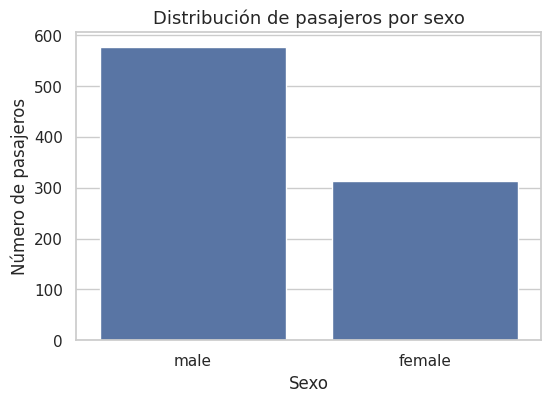

In [ ]:
# 1. Gráfico de conteo de 'Sex'.
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Sex')
plt.title('Distribución de pasajeros por sexo')
plt.xlabel('Sexo')
plt.ylabel('Número de pasajeros')
plt.show()

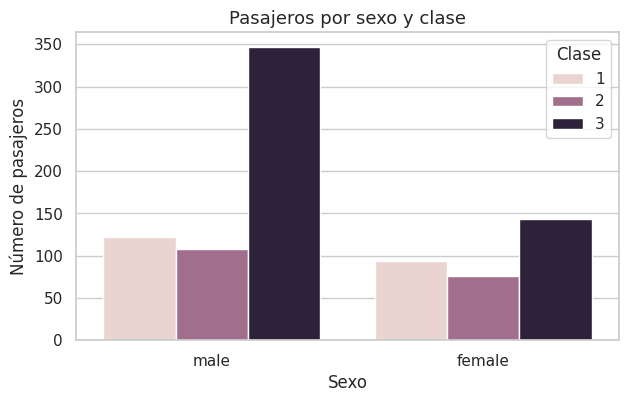

In [ ]:
# 2. Gráfico de conteo de 'Sex' con hue='Pclass'.
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x='Sex', hue='Pclass')
plt.title('Pasajeros por sexo y clase')
plt.xlabel('Sexo')
plt.ylabel('Número de pasajeros')
plt.legend(title='Clase')
plt.show()

In [ ]:
# 3. Tabla cruzada Sex x Pclass NORMALIZADA POR COLUMNAS:
#    ¿qué proporción de cada clase son mujeres?
tabla = pd.crosstab(df['Sex'], df['Pclass'], normalize='columns')
print((tabla * 100).round(1))

Pclass     1     2     3
Sex                     
female  43.5  41.3  29.3
male    56.5  58.7  70.7


### Paso 7. Distribución de edades

**Lógica:** un **histograma** divide la variable numérica en intervalos (*bins*) y cuenta cuántos casos caen en cada uno. `Age` tiene nulos: Seaborn los ignora al graficar, pero es bueno hacerlo explícito con `dropna()`.


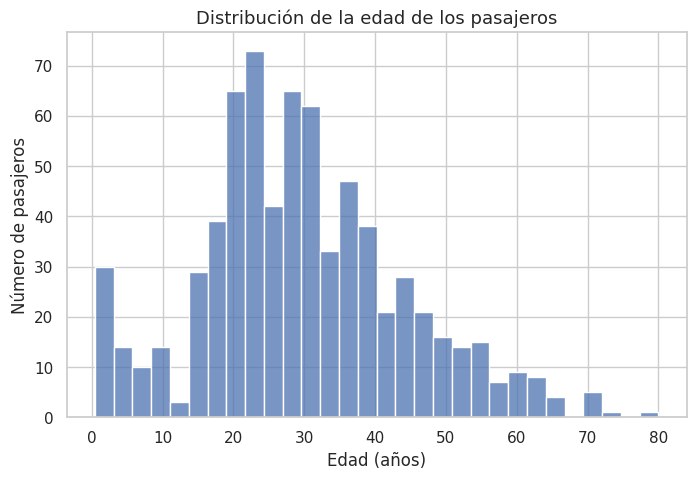

In [ ]:
# 1. Histograma de la edad: sns.histplot(df['Age'].dropna(), bins=30)
#    Añade título y etiquetas de los ejes.plt.figure(figsize=(8, 5))
sns.histplot(df['Age'].dropna(), bins=30)
plt.title('Distribución de la edad de los pasajeros')
plt.xlabel('Edad (años)')
plt.ylabel('Número de pasajeros')
plt.show()

In [ ]:
# 2. Calcula la edad promedio (Pandas ignora los NaN automáticamente).
edad_promedio = df['Age'].mean()
print(f"Edad promedio: {edad_promedio:.1f} años")

Edad promedio: 29.7 años


In [ ]:
# 3. Explora: mediana, mínimo y máximo de la edad.

print(f"Mediana: {df['Age'].median():.1f} años")
print(f"Mínimo:  {df['Age'].min():.2f} años")
print(f"Máximo:  {df['Age'].max():.1f} años")

Mediana: 28.0 años
Mínimo:  0.42 años
Máximo:  80.0 años


### Paso 8. Crear la variable `Person` (hombre, mujer o niño)

**Lógica:** `np.where(condición, valor_si_True, valor_si_False)` crea una columna de forma **vectorizada** (sin `for`). Aquí: si `Age < 16` → `'child'`; si no, se conserva el valor de `Sex`.


In [ ]:
# Crea df['Person'] con np.where:
#   condición: df['Age'] < 16
#   si True: 'child'      si False: df['Sex']

df['Person'] = np.where(df['Age'] < 16, 'child', df['Sex'])
print(df['Person'].value_counts())
print(df[['Age', 'Sex', 'Person']].head(10))

Person
male      537
female    271
child      83
Name: count, dtype: int64
    Age     Sex  Person
0  22.0    male    male
1  38.0  female  female
2  26.0  female  female
3  35.0  female  female
4  35.0    male    male
5   NaN    male    male
6  54.0    male    male
7   2.0    male   child
8  27.0  female  female
9  14.0  female   child


In [ ]:
# Luego cuenta cuántos hay de cada tipo con value_counts().
print(df['Person'].value_counts())
print((df['Person'].value_counts(normalize=True) * 100).round(1))

Person
male      537
female    271
child      83
Name: count, dtype: int64
Person
male      60.3
female    30.4
child      9.3
Name: proportion, dtype: float64


> **Advertencia — los NaN y las comparaciones.** En Pandas/NumPy, `NaN < 16` da `False`. Por lo tanto, **un pasajero sin edad nunca será `child`**: se queda con su sexo. Es un sesgo silencioso. Lo investigarás en E2.5.


### Paso 9. ¿Cuántos niños viajaban en cada clase?


In [ ]:
# Tabla cruzada de 'Pclass' (filas) contra 'Person' (columnas).
tabla_clase_persona = pd.crosstab(df['Pclass'], df['Person'])
print(tabla_clase_persona)

Person  child  female  male
Pclass                     
1           6      91   119
2          19      66    99
3          58     114   319


### Paso 10. Gráficos de densidad (KDE) de la edad

> **Teoría — KDE.** La *estimación de densidad por kernel* es un "histograma suavizado": la curva muestra dónde se concentran los valores. Con `hue` se superponen varias curvas. Usa `common_norm=False` para que **cada grupo se normalice por separado** (si no, los grupos grandes "aplastan" a los pequeños).



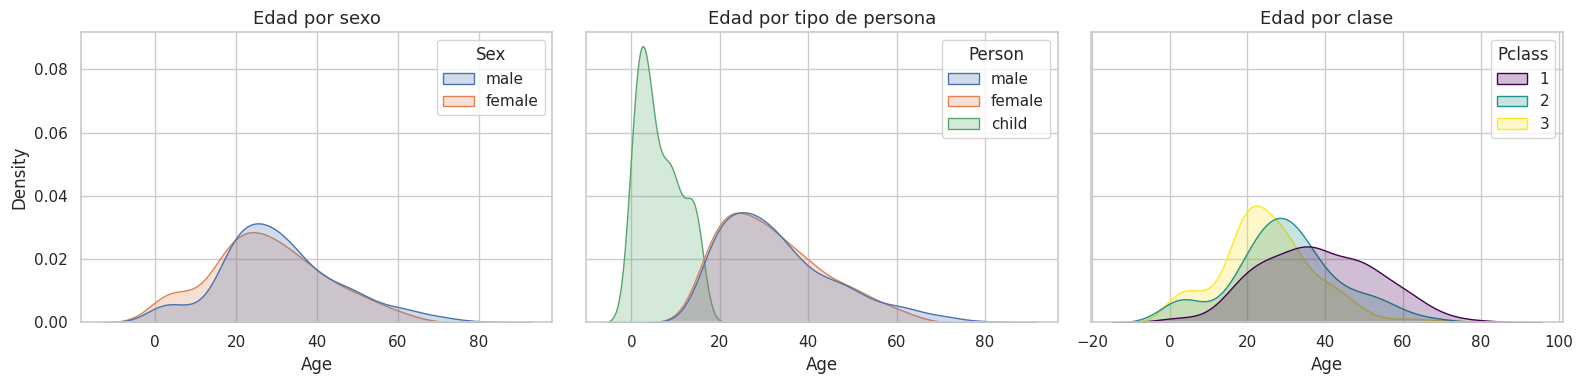

In [ ]:
# Crea una figura de 1 fila x 3 columnas: fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)

# Dibuja en cada eje (parámetro ax=axes[i]) un sns.kdeplot(data=df, x='Age', hue=..., fill=True, common_norm=False):
#   axes[0] -> hue='Sex'
#   axes[1] -> hue='Person'
#   axes[2] -> hue='Pclass'   (añade palette='viridis')

# Ponle un título a cada eje con axes[i].set_title(...) y cierra con plt.tight_layout(); plt.show()
# Figura de 1 fila x 3 columnas
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)

# 1) KDE de la edad por sexo
sns.kdeplot(data=df, x='Age', hue='Sex', fill=True, common_norm=False, ax=axes[0])
axes[0].set_title('Edad por sexo')

# 2) KDE de la edad por tipo de persona
sns.kdeplot(data=df, x='Age', hue='Person', fill=True, common_norm=False, ax=axes[1])
axes[1].set_title('Edad por tipo de persona')

# 3) KDE de la edad por clase
sns.kdeplot(data=df, x='Age', hue='Pclass', fill=True, common_norm=False,
            palette='viridis', ax=axes[2])
axes[2].set_title('Edad por clase')

plt.tight_layout()
plt.show()

### Evaluación — Parte 2


- **E2.1 (conceptual).** ¿Hay diferencias en la composición de género entre clases? Apóyate en la tabla normalizada del Paso 6.


Sí hay diferencias. Según la tabla normalizada por columnas, las mujeres representan ≈43 % de la primera clase, ≈41 % de la segunda y solo ≈29 % de la tercera, que es la clase más masculina (≈71 % hombres). Esto muestra que sexo y clase están relacionados, por lo que al analizar la supervivencia hay que separar ambos efectos y no atribuir a una sola variable lo que puede deberse a la otra

- **E2.2 (código).** Calcula la proporción de menores de 16 años en cada clase (no el conteo).


In [ ]:
# Retos E2.2 -> (df['Age'] < 16).groupby(df['Pclass']).mean()
print(((df['Age'] < 16).groupby(df['Pclass']).mean() * 100).round(1))

Pclass
1     2.8
2    10.3
3    11.8
Name: Age, dtype: float64


- **E2.3 (conceptual).** Describe la distribución de edades del Titanic. ¿Cómo era el pasajero "típico"?


La edad de los pasajeros tiene una distribución unimodal, casi simétrica y con ligera cola a la derecha: media ≈ 29.7, mediana 28, rango de 0.42 a 80 años y la mitad de los pasajeros entre ≈20 y ≈38 años. Hay además un pequeño grupo de niños menores de 5 años. El pasajero típico era un hombre adulto joven (≈28 años) de tercera clase, que viajaba solo y pagó una tarifa baja.

- **E2.4 (conceptual).** Según los KDE por clase, ¿qué clase tiene pasajeros de más edad? Propón una explicación social (no estadística) para esa diferencia.


La primera clase tiene pasajeros de más edad (media ≈ 38 años, frente a ≈ 25 en tercera). Socialmente, se explica porque la riqueza y el estatus se acumulan con los años: en primera viajaban empresarios y personas acomodadas de mediana edad, mientras que la tercera estaba formada sobre todo por emigrantes jóvenes que buscaban trabajo en América

- **E2.5 (código + conceptual).** ¿Cuántos pasajeros **sin edad** quedaron clasificados como `male` o `female` en `Person`? ¿Por qué eso puede subestimar el número de niños?


In [ ]:
# Retos E2.5-> filtra df[df['Age'].isnull()] y cuenta sus valores de 'Person'
sin_edad = df[df['Age'].isnull()]
print(sin_edad['Person'].value_counts())
print(f"Total sin edad: {len(sin_edad)}")

Person
male      124
female     53
Name: count, dtype: int64
Total sin edad: 177


Los 177 pasajeros sin edad quedaron clasificados como male o female (≈ 124 hombres y ≈ 53 mujeres) y ninguno como child, porque NaN < 16 es False. Esto puede subestimar el número de niños: algunos de los pasajeros sin edad eran menores, sobre todo en tercera clase, que concentra tanto los faltantes como los niños. Así, el grupo child queda más pequeño y male/female incluyen algunos niños, lo que distorsiona las tasas de supervivencia

## Parte 3 — Ubicación, embarque y composición familiar (Pasos 11–15)

> **Teoría — extraer información de texto.** Con una Serie de texto, el accesor `.str` aplica operaciones a cada elemento a la vez: `serie.str[0]` toma el primer carácter. En `Cabin` (por ejemplo `'C85'`) la primera letra indica la **cubierta**.



### Paso 11. Extraer la cubierta de la cabina


In [ ]:
# 1. Guarda en 'cabinas' las cabinas NO nulas: df['Cabin'].dropna()
cabinas = df['Cabin'].dropna()
print(len(cabinas))
print(cabinas.head())

204
1      C85
3     C123
6      E46
10      G6
11    C103
Name: Cabin, dtype: object


In [ ]:
# 2. Crea 'cubierta' tomando la primera letra de cada cabina (.str[0]).
cubierta = cabinas.str[0]
print(cubierta.value_counts())

Cabin
C    59
B    47
D    33
E    32
A    15
F    13
G     4
T     1
Name: count, dtype: int64


In [ ]:
# 3. Muestra los conteos por cubierta con value_counts().
#    NO modifiques df todavía: lo haremos en la Parte 5.
print(cubierta.value_counts())

Cabin
C    59
B    47
D    33
E    32
A    15
F    13
G     4
T     1
Name: count, dtype: int64


### Paso 12. Gráfico de conteo por cubierta (con depuración de anómalos)


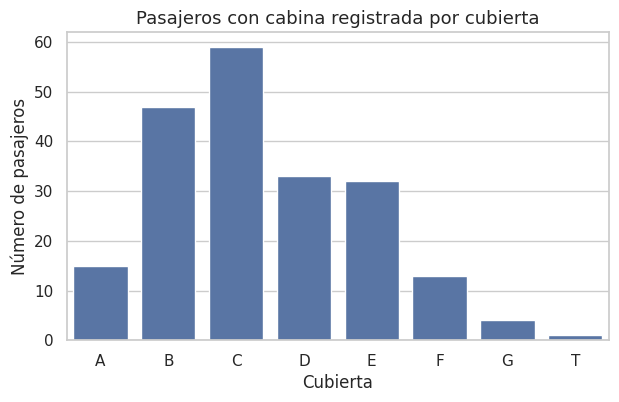

In [ ]:
# 1. Dibuja sns.countplot(x=cubierta, order=sorted(cubierta.unique())) con título y etiquetas.

# 2. Si encuentras una cubierta con un solo registro (anómala), elimínala de 'cubierta'
#    (cubierta = cubierta[cubierta != '?']) y vuelve a graficar.
plt.figure(figsize=(7, 4))
sns.countplot(x=cubierta, order=sorted(cubierta.unique()))
plt.title('Pasajeros con cabina registrada por cubierta')
plt.xlabel('Cubierta')
plt.ylabel('Número de pasajeros')
plt.show()



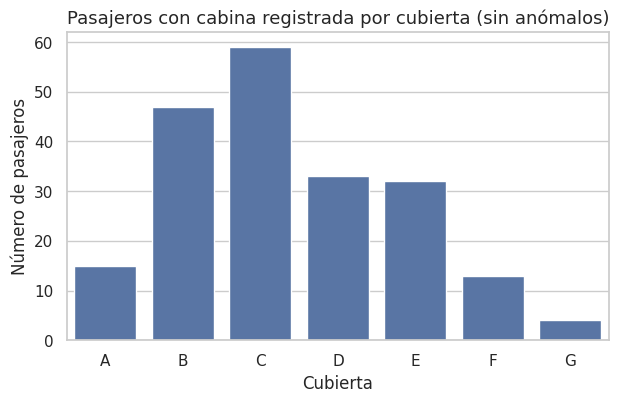

In [ ]:
cubierta = cubierta[cubierta != 'T']

plt.figure(figsize=(7, 4))
sns.countplot(x=cubierta, order=sorted(cubierta.unique()))
plt.title('Pasajeros con cabina registrada por cubierta (sin anómalos)')
plt.xlabel('Cubierta')
plt.ylabel('Número de pasajeros')
plt.show()

### Paso 13. Puerto de embarque y clase


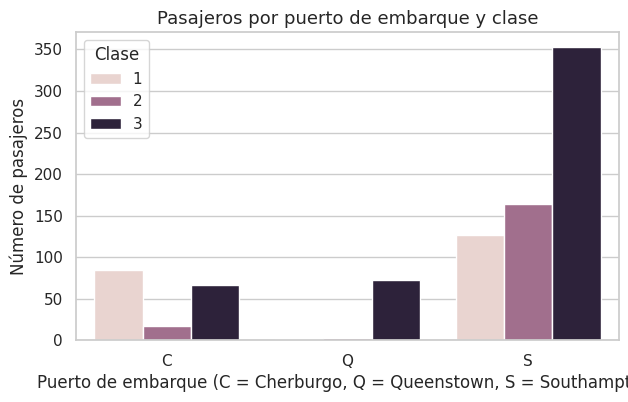

In [ ]:
# 1. Gráfico de conteo de 'Embarked' con hue='Pclass'.

# 2. Tabla cruzada Embarked x Pclass normalizada por FILAS (normalize='index'):
#    ¿qué composición de clases tiene cada puerto?

plt.figure(figsize=(7, 4))
sns.countplot(data=df, x='Embarked', hue='Pclass', order=['C', 'Q', 'S'])
plt.title('Pasajeros por puerto de embarque y clase')
plt.xlabel('Puerto de embarque (C = Cherburgo, Q = Queenstown, S = Southampton)')
plt.ylabel('Número de pasajeros')
plt.legend(title='Clase')
plt.show()

In [ ]:
tabla_puerto = pd.crosstab(df['Embarked'], df['Pclass'], normalize='index')
print((tabla_puerto * 100).round(1))

Pclass       1     2     3
Embarked                  
C         50.6  10.1  39.3
Q          2.6   3.9  93.5
S         19.7  25.5  54.8


### Paso 14. Crear la variable `Alone` (solo vs. con familia)

**Lógica:** `SibSp + Parch` es el número de familiares a bordo. Si es 0, viaja solo.


In [ ]:
# 1. Crea df['Familia'] = df['SibSp'] + df['Parch']
df['Familia'] = df['SibSp'] + df['Parch']

In [ ]:
# 2. Crea df['Alone'] con np.where: 'with Family' si Familia > 0, 'Alone' si no.
df['Alone'] = np.where(df['Familia'] > 0, 'with Family', 'Alone')


In [ ]:
# 3. Calcula la proporción de cada categoría con value_counts(normalize=True).
print(df['Alone'].value_counts(normalize=True).round(3))

Alone
Alone          0.603
with Family    0.397
Name: proportion, dtype: float64


### Paso 15. Visualizar la distribución de `Alone`


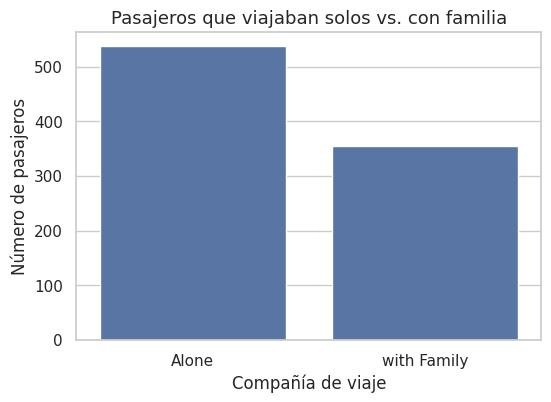

In [ ]:
# Gráfico de conteo de 'Alone' (con título y etiquetas).
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Alone', order=['Alone', 'with Family'])
plt.title('Pasajeros que viajaban solos vs. con familia')
plt.xlabel('Compañía de viaje')
plt.ylabel('Número de pasajeros')
plt.show()

### Evaluación — Parte 3


- **E3.1 (código).** ¿Qué porcentaje de pasajeros tiene información de cabina?


In [ ]:
# Reto E3.1 — Pista: df['Cabin'].notna().mean() * 100
porcentaje_cabina = df['Cabin'].notna().mean() * 100
print(f"Pasajeros con información de cabina: {porcentaje_cabina:.1f} %")

Pasajeros con información de cabina: 22.9 %


- **E3.2 (conceptual).** ¿Qué cubiertas eran las más ocupadas? ¿Qué implicaciones tiene que falten tantos datos de cabina? ¿Esa "ocupación" refleja de verdad el barco?


Las cubiertas con más registros son C (59) y B (47), seguidas de D y E. Pero que falte el 77 % de las cabinas limita mucho el análisis: los datos existentes se concentran en primera clase, por lo que las cubiertas altas aparecen sobrerrepresentadas y las bajas (donde viajaba la tercera clase) casi invisibles. Por eso la ‘ocupación’ observada no refleja la distribución real de pasajeros en el barco

- **E3.3 (conceptual).** En el Paso 12, ¿era correcto eliminar la cubierta anómala? Da un argumento a favor y uno en contra.


Eliminar la cubierta T fue razonable porque, con un solo registro, no permite calcular proporciones ni tasas de supervivencia con sentido, y solo añade ruido al gráfico. En contra, el dato no es un error sino un pasajero real, así que borrarlo implica perder información; una alternativa habría sido agruparlo con otra cubierta o conservarlo señalando que tiene un único caso

- **E3.4 (conceptual).** ¿Existe relación entre el puerto de embarque y la clase? Describe qué puerto se parece más a "tercera clase" y cuál a "primera".


Sí, hay relación entre puerto y clase. Queenstown es el más parecido a la tercera clase (≈ 93 % de sus pasajeros), reflejo de la emigración irlandesa. Cherburgo es el más parecido a la primera clase (≈ 50 % de sus pasajeros), por el perfil acomodado de quienes embarcaban allí. Southampton, el puerto más grande, tiene una composición intermedia, cercana a la del barco completo. Esto indica que el puerto puede ser una variable confusora al analizar la supervivencia

- **E3.5 (conceptual).** ¿Qué proporción viajaba sola? Formula una **hipótesis** (con su razón) sobre si viajar en familia afectó la supervivencia. La verificarás en la Parte 9.


Aproximadamente el 60 % de los pasajeros viajaba solo. Hipótesis: quienes viajaban con familia sobrevivieron más que quienes viajaban solos, porque entre ellos había más mujeres y niños, que tenían prioridad en la evacuación, y porque el apoyo mutuo facilitaba llegar a los botes. Se espera, sin embargo, que las familias muy numerosas tengan peor supervivencia. Esto se verificará en la Parte 9 comparando tasas de supervivencia por Alone y Familia, controlando por sexo y clase

## Parte 4 — Análisis de supervivencia: el núcleo del taller (Pasos 16–20)

> **Teoría — la media de una variable 0/1 es una proporción.** Si `Survived` vale 1 para quien sobrevivió y 0 para quien no, entonces `df['Survived'].mean()` es la **tasa de supervivencia**. Por eso los gráficos de Seaborn que promedian (`catplot` tipo punto, `lmplot`) usan la columna **numérica** `Survived` en el eje y; la columna de texto `Survivor` sirve para etiquetar gráficos de conteo.
>
> **Las barritas verticales** de los gráficos de puntos son **intervalos de confianza al 95 %**: indican la *incertidumbre*. Barras largas = pocos datos o mucha variabilidad.



### Paso 16. Panorama general


In [ ]:
# 1. Crea df['Survivor'] mapeando 0 -> 'No' y 1 -> 'Yes' con .map({...}).
df['Survivor'] = df['Survived'].map({0: 'No', 1: 'Yes'})

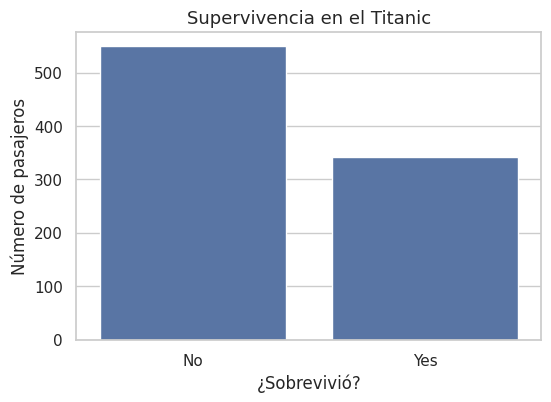

In [ ]:
# 2. Gráfico de conteo de 'Survivor'.
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Survivor', order=['No', 'Yes'])
plt.title('Supervivencia en el Titanic')
plt.xlabel('¿Sobrevivió?')
plt.ylabel('Número de pasajeros')
plt.show()

In [ ]:
# 3. Calcula la tasa general de supervivencia (media de 'Survived').
tasa_general = df['Survived'].mean()
print(f"Tasa general de supervivencia: {tasa_general:.3f} ({tasa_general * 100:.1f} %)")

Tasa general de supervivencia: 0.384 (38.4 %)


### Paso 17. Supervivencia por clase


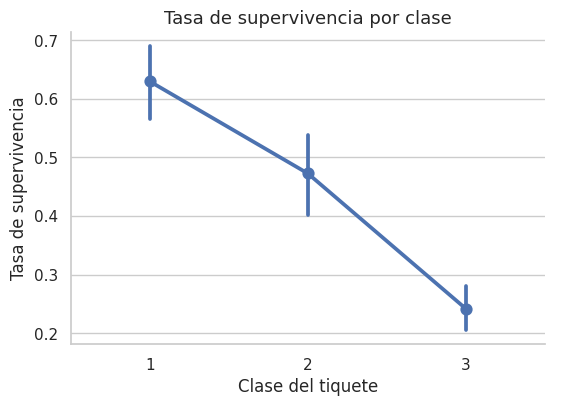

Text(0.5, 1.02, 'Tasa de supervivencia por clase')

In [ ]:
# Gráfico de puntos: sns.catplot(data=df, x='Pclass', y='Survived', kind='point', height=4, aspect=1.4)
# Añade título con plt.title(...) y etiqueta del eje y: "Tasa de supervivencia".
g = sns.catplot(data=df, x='Pclass', y='Survived', kind='point', height=4, aspect=1.4)
plt.title('Tasa de supervivencia por clase')
g.set_axis_labels('Clase del tiquete', 'Tasa de supervivencia')
plt.show()

g.fig.suptitle('Tasa de supervivencia por clase', y=1.02)

### Paso 18. Supervivencia por clase y tipo de persona


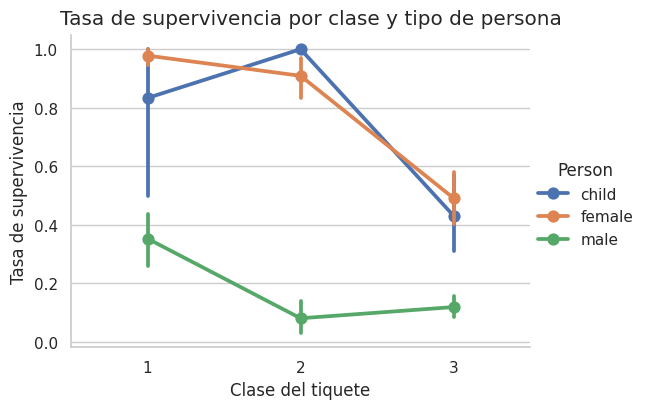

In [ ]:
# Repite el gráfico anterior añadiendo hue='Person' y hue_order=['child', 'female', 'male'].
g = sns.catplot(data=df, x='Pclass', y='Survived', hue='Person',
                hue_order=['child', 'female', 'male'],
                kind='point', height=4, aspect=1.4)
g.set_axis_labels('Clase del tiquete', 'Tasa de supervivencia')
g.fig.suptitle('Tasa de supervivencia por clase y tipo de persona', y=1.02)
plt.show()

### Paso 19. Edad y supervivencia

> **Teoría — `lmplot`.** Dibuja una **recta de regresión** (con banda de confianza) de y contra x. Con `y` binaria (0/1) la recta es solo una *aproximación visual* de la tendencia. El parámetro `x_bins` agrupa la edad en intervalos y dibuja la **tasa media por intervalo**, lo cual es mucho más legible.


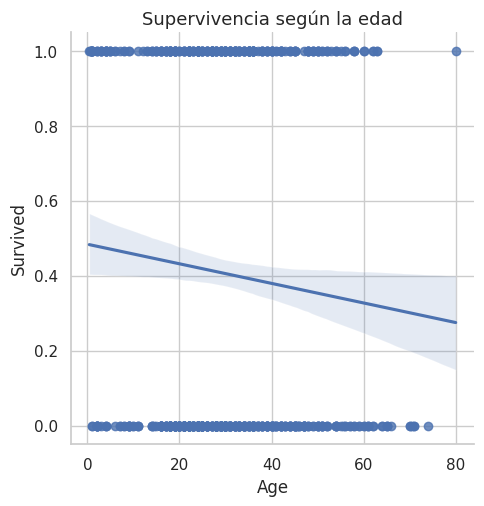

In [ ]:
# 1. sns.lmplot(data=df, x='Age', y='Survived')
sns.lmplot(data=df, x='Age', y='Survived')
plt.title('Supervivencia según la edad')
plt.show()

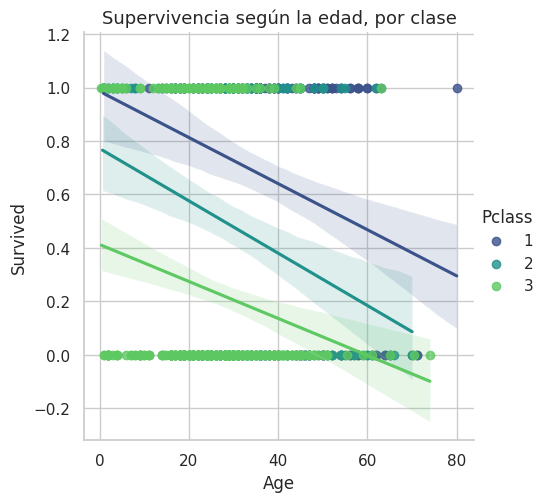

In [ ]:
# 2. Añade hue='Pclass'.
sns.lmplot(data=df, x='Age', y='Survived', hue='Pclass', palette='viridis')
plt.title('Supervivencia según la edad, por clase')
plt.show()

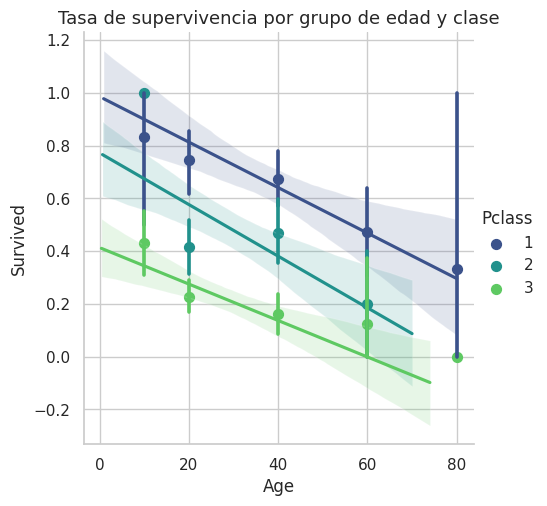

In [ ]:
# 3. Define generaciones = [10, 20, 40, 60, 80] y usa x_bins=generaciones con hue='Pclass'.
generaciones = [10, 20, 40, 60, 80]
sns.lmplot(data=df, x='Age', y='Survived', hue='Pclass', palette='viridis',
           x_bins=generaciones)
plt.title('Tasa de supervivencia por grupo de edad y clase')
plt.show()

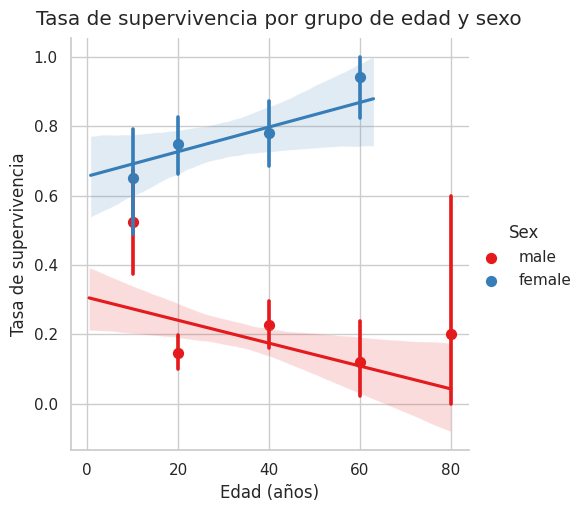

In [ ]:
# 4. Repite el punto 3 con hue='Sex'.
generaciones = [10, 20, 40, 60, 80]
g = sns.lmplot(data=df, x='Age', y='Survived', hue='Sex',
               x_bins=generaciones, palette='Set1')
g.set_axis_labels('Edad (años)', 'Tasa de supervivencia')
g.fig.suptitle('Tasa de supervivencia por grupo de edad y sexo', y=1.02)
plt.show()

### Paso 20. Relación tarifa-edad


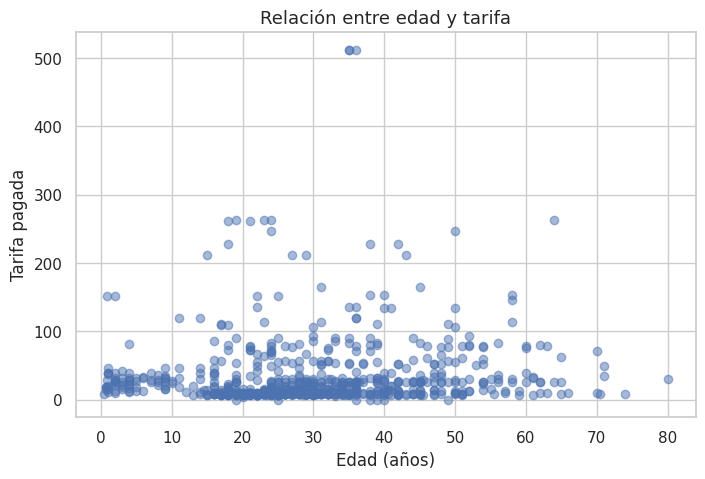

In [ ]:
# 1. Dispersión simple: plt.scatter(df['Age'], df['Fare'], alpha=0.5)
plt.figure(figsize=(8, 5))
plt.scatter(df['Age'], df['Fare'], alpha=0.5)
plt.title('Relación entre edad y tarifa')
plt.xlabel('Edad (años)')
plt.ylabel('Tarifa pagada')
plt.show()

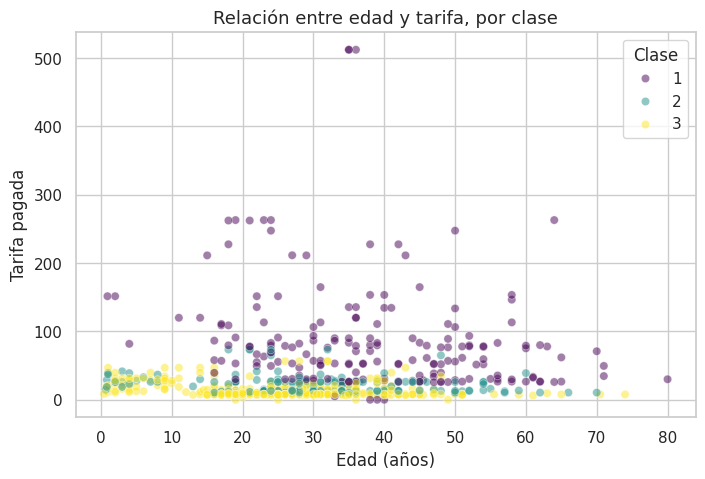

In [ ]:
# 2. Desafío: sns.scatterplot(data=df, x='Age', y='Fare', hue='Pclass', alpha=0.5, palette='viridis')
# Añade título y etiquetas.
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Age', y='Fare', hue='Pclass', alpha=0.5, palette='viridis')
plt.title('Relación entre edad y tarifa, por clase')
plt.xlabel('Edad (años)')
plt.ylabel('Tarifa pagada')
plt.legend(title='Clase')
plt.show()

### Evaluación — Parte 4


- **E4.1 (conceptual).** ¿Cuál fue la tasa general de supervivencia? ¿Qué clase tuvo mejor tasa y por qué crees que ocurrió?


La tasa general de supervivencia fue de ≈ 38.4 % (342 de 891). La primera clase tuvo la mejor tasa (≈ 63 %), frente a ≈ 47 % en segunda y ≈ 24 % en tercera. Probablemente se debió a que las cabinas de primera estaban más cerca de los botes salvavidas, a que sus pasajeros recibieron antes la alarma y tuvieron mejor acceso a la tripulación, y a que había proporcionalmente más mujeres en esa clase. La clase tiene efecto propio, pero se mezcla con el sexo y la edad.



- **E4.2 (código).** Construye una **tabla** con la tasa de supervivencia por `Pclass` (filas) y `Person` (columnas). ¿Se cumplió "mujeres y niños primero"? ¿Hay excepciones?


In [ ]:
# Reto E4.2 — Pista: df.pivot_table(values='Survived', index='Pclass', columns='Person', aggfunc='mean')
tabla_super = df.pivot_table(values='Survived', index='Pclass', columns='Person', aggfunc='mean')
print(tabla_super.round(2))

Person  child  female  male
Pclass                     
1        0.83    0.98  0.35
2        1.00    0.91  0.08
3        0.43    0.49  0.12


In [ ]:
# Reto extra: añade aggfunc=['mean', 'count'] para ver también el tamaño de cada grupo.
tabla_extra = df.pivot_table(values='Survived', index='Pclass', columns='Person',
                             aggfunc=['mean', 'count'])
print(tabla_extra.round(2))

        mean              count            
Person child female  male child female male
Pclass                                     
1       0.83   0.98  0.35     6     91  119
2       1.00   0.91  0.08    19     66   99
3       0.43   0.49  0.12    58    114  319


- **E4.3 (conceptual).** ¿Era ser hombre en tercera clase particularmente peligroso? ¿Los niños recibieron el mismo trato en todas las clases?


Sí, ser hombre en tercera clase fue muy peligroso: solo ≈ 12 % sobrevivió, y es el grupo más numeroso del barco (≈ 36 % de los pasajeros). Aun así, los hombres de segunda tuvieron una tasa todavía menor (≈ 7 %), por lo que el mayor riesgo se dio en los hombres fuera de primera clase. Los niños no recibieron el mismo trato: sobrevivieron casi todos en primera y segunda, pero solo ≈ 37 % en tercera, por debajo incluso de las mujeres de su clase. Los niños de primera son muy pocos (≈ 4), así que esa cifra es poco fiable

- **E4.4 (conceptual).** En el Paso 19, ¿existe una tendencia entre edad y supervivencia? ¿Cambia por clase? ¿Y por género? ¿Qué cambia al variar los *bins*?


Existe una tendencia negativa débil entre edad y supervivencia: los mayores sobrevivieron algo menos. Cambia por clase (la pendiente es clara en primera y segunda, y casi plana y baja en tercera) y sobre todo por género (en hombres la supervivencia cae con la edad, mientras que en mujeres se mantiene alta o sube levemente). Al variar los bins cambian los puntos, no la recta: pocos bins dan puntos estables pero pierden detalle, y muchos bins muestran más matices pero con ruido y barras de error largas. La conclusión general se mantiene.

- **E4.5 (conceptual).** En el Paso 18, el intervalo de confianza de los niños de primera clase es muy ancho. ¿Por qué? ¿Qué cuidado implica para interpretar ese punto?


El intervalo de confianza de los niños de primera clase es muy ancho porque solo hay unos 4 casos: un único niño más o menos que sobreviviera cambia la tasa en 25 puntos. El cuidado es no interpretar ese punto como una tasa fiable ni compararlo con otras clases, ya que los intervalos se solapan y los datos no permiten afirmar diferencias. Siempre hay que mirar el tamaño del grupo junto con la barra de error

- **E4.6 (conceptual).** ¿Qué revela el gráfico tarifa-edad coloreado por clase sobre la relación entre tarifa, edad y clase?


El gráfico muestra que la tarifa depende casi por completo de la clase: las tarifas altas son de primera clase, la tercera se concentra en tarifas bajas y la segunda queda en medio. La edad casi no se relaciona con la tarifa (correlación débil), pero sí con la clase: la primera tiene pasajeros de más edad y la tercera más jóvenes. También se ven outliers cerca de 512 libras y tarifas de 0. Por eso Fare y Pclass son variables muy redundantes y hay que tener cuidado al usarlas juntas

## Parte 5 — Limpieza y preparación de datos (Pasos 21–26)

> **Teoría — tres decisiones de limpieza.** Un dato faltante puede (a) eliminarse, (b) rellenarse con un valor "razonable" (*imputación*) o (c) conservarse como una categoría propia ("desconocido"). **Ninguna opción es neutral:** cada una cambia lo que los datos dicen. Documenta siempre qué hiciste y por qué.
>
> **Teoría — codificación.** Los modelos y las correlaciones necesitan números. Convertir categorías a números con `.map({...})` crea columnas nuevas (con prefijo `N`). Cuidado: **un número impone un orden** que quizá no existe (¿es "Q = 2" mayor que "S = 0"?).


### Paso 21. Datos faltantes en `Embarked`


In [ ]:
# 1. ¿Cuántos valores faltan en 'Embarked'?
print(df['Embarked'].isnull().sum())

2


In [ ]:
# 2. Calcula la categoría más frecuente: df['Embarked'].mode()[0]
moda_embarked = df['Embarked'].mode()[0]
print(moda_embarked)

S


In [ ]:
# 3. Rellena los faltantes con esa moda usando fillna (asigna el resultado a la columna;
#    evita inplace=True)
df['Embarked'] = df['Embarked'].fillna(moda_embarked)
print(df['Embarked'].isnull().sum())   # debería dar 0

0


In [ ]:
# 4. Crea df['NEmbarked'] mapeando S -> 0, C -> 1, Q -> 2.
df['NEmbarked'] = df['Embarked'].map({'S': 0, 'C': 1, 'Q': 2})
print(df['NEmbarked'].value_counts())
print(df['NEmbarked'].isnull().sum())

NEmbarked
0    646
1    168
2     77
Name: count, dtype: int64
0


### Paso 22. Datos faltantes en `Age`

**Lógica:** en lugar de rellenar con el promedio global, rellenamos con el **promedio de su grupo** (género). Se calcula una tabla `promedio por género` y se "traduce" cada pasajero a su promedio con `.map`.


In [ ]:
# 1. Calcula la edad promedio por género: df.groupby('Sex')['Age'].mean()
edad_por_genero = df.groupby('Sex')['Age'].mean()
print(edad_por_genero.round(2))

Sex
female    27.92
male      30.73
Name: Age, dtype: float64


In [ ]:
# 2. Rellena los nulos de 'Age': df['Age'] = df['Age'].fillna(df['Sex'].map(promedios))
promedios = df.groupby('Sex')['Age'].mean()
df['Age'] = df['Age'].fillna(df['Sex'].map(promedios))

print(df['Age'].isnull().sum())

0


In [ ]:
# 3. Verifica que no queden nulos en 'Age'.
print(df['Age'].isnull().sum())

0


In [ ]:
# 4. Guarda la desviación estándar de 'Age' ANTES de rellenar para compararla en E5.3.
std_antes = df['Age'].std()
print(f"Desviación estándar antes de imputar: {std_antes:.2f}")

Desviación estándar antes de imputar: 13.01


### Paso 23. Convertir `Sex` a número


In [ ]:
# Crea df['NSex'] mapeando female -> 0 y male -> 1.
df['NSex'] = df['Sex'].map({'female': 0, 'male': 1})

print(df['NSex'].value_counts())
print(df['NSex'].isnull().sum())

NSex
1    577
0    314
Name: count, dtype: int64
0


### Paso 24. Tratamiento de `Cabin`


In [ ]:
# 1. Rellena los nulos de 'Cabin' con 'X' (desconocido).
df['Cabin'] = df['Cabin'].fillna('X')
print(df['Cabin'].isnull().sum())

0


In [ ]:
# 2. Crea df['TCabin'] con la primera letra de la cabina.
df['TCabin'] = df['Cabin'].str[0]
print(df['TCabin'].head())

0    X
1    C
2    X
3    C
4    X
Name: TCabin, dtype: object


In [ ]:
# 3. Cuenta los pasajeros por cubierta (value_counts).
print(df['TCabin'].value_counts())

TCabin
X    687
C     59
B     47
D     33
E     32
A     15
F     13
G      4
T      1
Name: count, dtype: int64


In [ ]:
# 4. Crea df['NCabin'] asignando un número a cada cubierta:
#    mapa = {letra: i for i, letra in enumerate(sorted(df['TCabin'].unique()))}
mapa = {letra: i for i, letra in enumerate(sorted(df['TCabin'].unique()))}
print(mapa)
df['NCabin'] = df['TCabin'].map(mapa)
print(df['NCabin'].value_counts().sort_index())

{'A': 0, 'B': 1, 'C': 2, 'D': 3, 'E': 4, 'F': 5, 'G': 6, 'T': 7, 'X': 8}
NCabin
0     15
1     47
2     59
3     33
4     32
5     13
6      4
7      1
8    687
Name: count, dtype: int64


### Paso 25. Extracción de títulos del nombre

> **Teoría — expresiones regulares (regex).** Los nombres tienen la forma `"Braund, Mr. Owen Harris"`. El título está entre la coma y el punto. El patrón `r',\s*([^.]+)\.'` significa: una coma, espacios opcionales (`\s*`), y captura (`( )`) todo lo que no sea un punto (`[^.]+`), hasta el punto. `str.extract(patron, expand=False)` devuelve la parte capturada.


In [ ]:
# 1. Crea df['TTitulo'] = df['Name'].str.extract(r',\s*([^.]+)\.', expand=False).str.strip()
df['TTitulo'] = df['Name'].str.extract(r',\s*([^.]+)\.', expand=False).str.strip()
print(df['TTitulo'].head())
print(df['TTitulo'].isnull().sum())

0      Mr
1     Mrs
2    Miss
3     Mrs
4      Mr
Name: TTitulo, dtype: object
0


In [ ]:
# 2. Analiza la frecuencia de cada título (value_counts).
print(df['TTitulo'].value_counts())

TTitulo
Mr              517
Miss            182
Mrs             125
Master           40
Dr                7
Rev               6
Col               2
Mlle              2
Major             2
Ms                1
Mme               1
Don               1
Lady              1
Sir               1
Capt              1
the Countess      1
Jonkheer          1
Name: count, dtype: int64


In [ ]:
# 3. Tabla cruzada de título vs. género (pd.crosstab(df['TTitulo'], df['Sex'])).
print(pd.crosstab(df['TTitulo'], df['Sex']))

Sex           female  male
TTitulo                   
Capt               0     1
Col                0     2
Don                0     1
Dr                 1     6
Jonkheer           0     1
Lady               1     0
Major              0     2
Master             0    40
Miss             182     0
Mlle               2     0
Mme                1     0
Mr                 0   517
Mrs              125     0
Ms                 1     0
Rev                0     6
Sir                0     1
the Countess       1     0


### Paso 26. Consolidar títulos

**Lógica:** los títulos raros dejan grupos de 1 o 2 personas: inútiles para estadística. Se agrupan en categorías más generales con `replace` (un diccionario) y `where/isin` (todo lo que no esté en la lista principal pasa a `'Otro'`).



In [ ]:
# 1. Reemplaza con un diccionario:
#      Master -> Mr ;  the Countess, Dona, Mme -> Mrs ;  Lady, Mlle, Ms -> Miss
df['TTitulo'] = df['TTitulo'].replace({
    'Master': 'Mr',
    'the Countess': 'Mrs', 'Dona': 'Mrs', 'Mme': 'Mrs',
    'Lady': 'Miss', 'Mlle': 'Miss', 'Ms': 'Miss'
})
print(df['TTitulo'].value_counts())

TTitulo
Mr          557
Miss        186
Mrs         127
Dr            7
Rev           6
Major         2
Col           2
Don           1
Sir           1
Capt          1
Jonkheer      1
Name: count, dtype: int64


In [ ]:
# 2. Todo título que NO esté en ['Mr', 'Mrs', 'Miss'] debe pasar a 'Otro'.
#    Pista: df['TTitulo'].where(df['TTitulo'].isin([...]), 'Otro')

df['TTitulo'] = df['TTitulo'].where(df['TTitulo'].isin(['Mr', 'Mrs', 'Miss']), 'Otro')

In [ ]:
# 3. Revisa los conteos finales.
print(df['TTitulo'].value_counts())
print(df['TTitulo'].isnull().sum())

TTitulo
Mr      557
Miss    186
Mrs     127
Otro     21
Name: count, dtype: int64
0


In [ ]:
# 4. Crea df['NTitulo'] mapeando Mr -> 0, Mrs -> 1, Miss -> 2, Otro -> 3.
df['NTitulo'] = df['TTitulo'].map({'Mr': 0, 'Mrs': 1, 'Miss': 2, 'Otro': 3})
print(df['NTitulo'].value_counts().sort_index())
print(df['NTitulo'].isnull().sum())

NTitulo
0    557
1    127
2    186
3     21
Name: count, dtype: int64
0


### Evaluación — Parte 5


- **E5.1 (conceptual).** ¿Es apropiado rellenar `Embarked` con el valor más común? Menciona **dos alternativas** y su costo.


Sí es apropiado rellenar Embarked con la moda (‘S’): solo faltan 2 registros (0.2 %) y S es la categoría dominante (≈ 72 %), por lo que el efecto es insignificante. Una alternativa es imputar según un grupo similar (por clase o tarifa), que usa más información pero es más compleja y podría dar otro puerto, como C, que no sería el correcto. Otra es crear una categoría ‘Desconocido’, que no inventa datos pero genera un grupo de 2 casos sin utilidad estadística. Eliminar las filas también es posible, pero pierde información. Ninguna opción es neutral, así que hay que documentar la decisión

- **E5.2 (código).** Rellenar la edad por género es una opción. Prueba otra: la **mediana por `Pclass` y `Sex`**. Compara los dos resultados para el mismo pasajero. (Pista: necesitas recargar los datos originales para no usar edades ya rellenadas.)


In [ ]:
# Reto E5.2 -> df.groupby(['Pclass', 'Sex'])['Age'].transform('median')

df_orig = sns.load_dataset('titanic')
print(df_orig.columns.tolist())

['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']


- **E5.3 (código + conceptual).** Compara la desviación estándar de `Age` antes y después de rellenar con promedios. ¿Qué pasó con la variabilidad? ¿Qué sesgo introduce el método?



Antes de imputar, la desviación estándar de Age era ≈ 14.5 años; después de rellenar con el promedio por sexo bajó a ≈ 13.0 (≈ 10 % menos), mientras que la media casi no cambió (≈ 29.7). La variabilidad se redujo porque 177 pasajeros recibieron solo dos valores cercanos a la media. El método sesga el análisis porque subestima la dispersión real, debilita relaciones con otras variables, hace más viejos a los pasajeros de tercera clase y oculta a los niños sin edad registrada. Para reducir el sesgo conviene imputar por grupos más finos, añadir ruido o usar imputación múltiple

In [ ]:

df_orig = sns.load_dataset('titanic')

# Renombra para usar los mismos nombres que en el resto del taller
df_orig = df_orig.rename(columns={'pclass': 'Pclass', 'sex': 'Sex', 'age': 'Age'})

# Comprobación: deben salir 891 filas y 177 nulos en Age
print(df_orig.shape[0], df_orig['Age'].isnull().sum())

# --- Desviación estándar ANTES de imputar ---
std_antes = df_orig['Age'].std()
print(f"Desviación estándar antes: {std_antes:.2f}")

891 177
Desviación estándar antes: 14.53


- **E5.4 (código + ética).** ¿Deberíamos eliminar `Cabin` por tener tantos faltantes? Calcula la tasa de supervivencia de quienes **sí** tienen cabina frente a quienes **no** (`TCabin != 'X'`) y argumenta si "tener cabina registrada" es información en sí misma.


In [ ]:
# Reto E5.4 -> df.groupby(df['TCabin'] != 'X')['Survived'].agg(['mean', 'count'])
tabla_cabina = df.groupby(df['TCabin'] != 'X')['Survived'].agg(['mean', 'count'])
tabla_cabina.index = ['Sin cabina (X)', 'Con cabina registrada']
print(tabla_cabina.round(3))

                        mean  count
Sin cabina (X)         0.300    687
Con cabina registrada  0.667    204


- **E5.5 (conceptual).** La consolidación `Master → Mr` junta a niños varones con hombres adultos. ¿Qué información se pierde? ¿Y es discutible que `Lady → Miss`?


Fusionar Master con Mr pierde la señal de edad: Master identifica niños varones, cuya supervivencia (≈ 0.58) es muy distinta a la de los adultos (≈ 0.16), y se pierde el efecto ‘niños primero’ y la pista para detectar niños sin edad. Mantenerlo como categoría propia era viable (40 casos). Que Lady → Miss es discutible: Lady es un título nobiliario que indica estatus, no soltería, y el criterio es inconsistente con the Countess → Mrs. Su impacto numérico es mínimo (1 persona), pero conceptualmente mezcla estatus con estado civil. Lo más defendible habría sido una categoría Noble o Otro, y siempre documentar la decisión

- **E5.6 (conceptual — sociológica).** ¿Qué nos revelan los títulos sobre la estructura social de la época?


Los títulos revelan una sociedad que clasificaba a las personas por sexo, edad y estado civil (Mr, Master, Miss, Mrs), donde las mujeres se definían por su relación con un hombre; que conservaba jerarquías heredadas (Lady, Sir, Countess) y prestigios profesionales (Dr, Rev, Major); y que estaba conectada internacionalmente (Mlle, Mme, Don). Además, esas categorías determinaron la supervivencia, porque el protocolo de evacuación se basaba en ellas. Pero los títulos no distinguen la clase económica (mucha gente de tercera es simplemente Mr o Mrs) y reflejan quién estaba mejor registrado, así que son una ventana parcial y sesgada a la estructura social

- **E5.7 (conceptual).** `NEmbarked`, `NCabin` y `NTitulo` asignan números a categorías **sin orden natural**. ¿Qué riesgo tiene eso al calcular correlaciones o entrenar un modelo? ¿Qué técnica lo evita? (Pista: *one-hot encoding*.)


NEmbarked, NCabin y NTitulo asignan enteros a categorías nominales, lo que impone un orden y distancias que no existen. Al calcular correlaciones, el resultado depende de la asignación arbitraria de códigos y puede ocultar relaciones reales; en modelos lineales o basados en distancia, el modelo interpreta los códigos como cantidades y aprende efectos sin sentido. La técnica que lo evita es el one-hot encoding (pd.get_dummies), que crea una columna binaria por categoría, de modo que todas queden equidistantes. Conviene usar drop_first=True en modelos lineales para evitar multicolinealidad y agrupar antes las categorías muy raras

## Parte 6 — Correlaciones y estadísticas por grupos (Pasos 27–29)

> **Teoría — correlación de Pearson (repaso del Taller #1).** `df[cols].corr()` produce una **matriz** con la correlación lineal de cada par de variables (−1 a +1). Un **heatmap** con `annot=True` la hace legible. Recuerda: mide relación **lineal**, no implica causalidad, y es poco informativa para variables categóricas codificadas arbitrariamente.



### Paso 27. Matriz de correlación


In [ ]:
# 1. Elige las variables numéricas relevantes:
#    cols = ['Survived', 'Pclass', 'NSex', 'Age', 'SibSp', 'Parch', 'Fare', 'NEmbarked', 'NCabin', 'NTitulo']

cols = ['Survived', 'Pclass', 'NSex', 'Age', 'SibSp', 'Parch', 'Fare', 'NEmbarked', 'NCabin', 'NTitulo']

In [ ]:
# 2. Calcula corr = df[cols].corr()

corr = df[cols].corr()



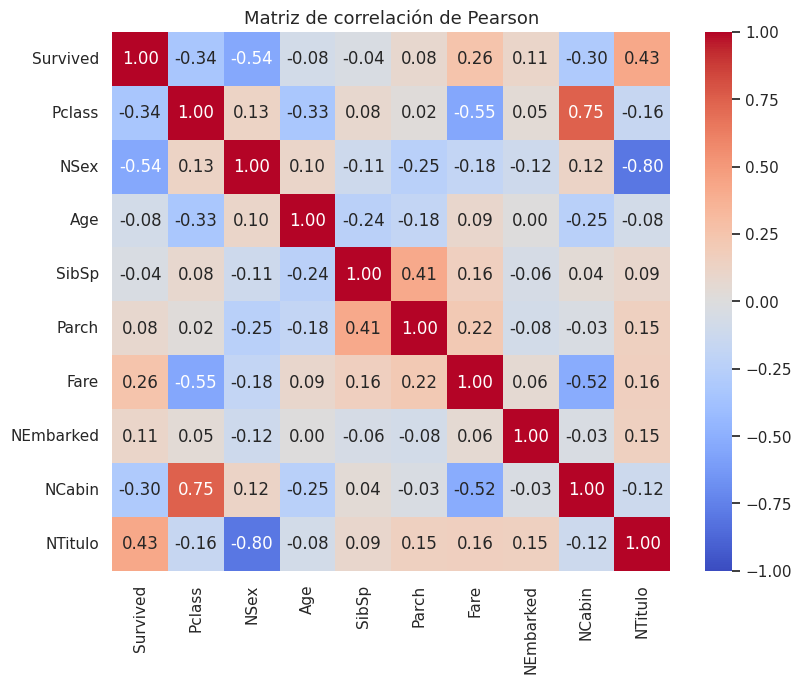

In [ ]:
# 3. Dibuja sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
#    con plt.figure(figsize=(9, 7)).

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Matriz de correlación de Pearson')
plt.show()

In [ ]:
# 4. Imprime solo la columna de 'Survived' ordenada: corr['Survived'].sort_values()

print(corr['Survived'].sort_values())

NSex        -0.543351
Pclass      -0.338481
NCabin      -0.301116
Age         -0.080453
SibSp       -0.035322
Parch        0.081629
NEmbarked    0.106811
Fare         0.257307
NTitulo      0.428661
Survived     1.000000
Name: Survived, dtype: float64


### Paso 28. Estadísticas descriptivas por grupos

Genera cuatro tablas con `groupby`:

In [ ]:
# 1. Edad según supervivencia:   df.groupby('Survived')['Age'].describe()
print(df.groupby('Survived')['Age'].describe().round(2))

          count   mean    std   min   25%    50%   75%   max
Survived                                                    
0         549.0  30.56  12.46  1.00  23.0  30.73  35.0  74.0
1         342.0  28.41  13.77  0.42  21.0  27.92  35.0  80.0


In [ ]:
# 2. Supervivencia por sexo:     df.groupby('Sex')['Survived'].agg(['mean', 'sum', 'count'])
print(df.groupby('Sex')['Survived'].agg(['mean', 'sum', 'count']).round(3))

         mean  sum  count
Sex                      
female  0.742  233    314
male    0.189  109    577


In [ ]:
# 3. Supervivencia por clase:    igual que (2) con 'Pclass'
print(df.groupby('Pclass')['Survived'].agg(['mean', 'sum', 'count']).round(3))

         mean  sum  count
Pclass                   
1       0.630  136    216
2       0.473   87    184
3       0.242  119    491


In [ ]:
# 4. Supervivencia por 'Alone':  igual que (2) con 'Alone'
print(df.groupby('Alone')['Survived'].agg(['mean', 'sum', 'count']).round(3))

              mean  sum  count
Alone                         
Alone        0.304  163    537
with Family  0.506  179    354


### Paso 29. ¿Es la diferencia por sexo estadísticamente significativa? (Chi-cuadrado)

> **Teoría — prueba de independencia chi-cuadrado.** Compara los conteos observados en una tabla cruzada con los que se esperarían **si las dos variables fueran independientes**.
> - **H₀:** `Sex` y `Survived` son independientes (el sexo no se asocia con sobrevivir).
> - **H₁:** sí hay asociación.
>
> Si `p < 0.05` se rechaza H₀. **Un p-valor pequeño no dice que la asociación sea grande ni causal**, solo que es poco probable que sea azar.


In [ ]:
# 1. Construye la tabla de contingencia: tabla = pd.crosstab(df['Sex'], df['Survived'])
tabla = pd.crosstab(df['Sex'], df['Survived'])
print(tabla)

Survived    0    1
Sex               
female     81  233
male      468  109


In [ ]:
# 2. Aplica: chi2, p, gl, esperados = stats.chi2_contingency(tabla)
chi2, p, gl, esperados = stats.chi2_contingency(tabla)
esperados_df = pd.DataFrame(esperados, index=tabla.index, columns=tabla.columns).round(1)
print(esperados_df)

Survived      0      1
Sex                   
female    193.5  120.5
male      355.5  221.5


In [ ]:
# 3. Imprime chi2 y p, y escribe en un comentario tu conclusión.
print(f"chi2 = {chi2:.2f}")
print(f"grados de libertad = {gl}")
print(f"p-valor = {p:.2e}")
# Conclusión:
# Como p < 0.05, se rechaza H0: Sex y Survived NO son independientes.
# Existe una asociación estadísticamente significativa entre el sexo y la
# supervivencia: la diferencia observada (≈ 74 % mujeres vs ≈ 19 % hombres)
# es muy improbable que se deba al azar. Esto no prueba causalidad ni mide
# por sí solo la magnitud del efecto.

chi2 = 260.72
grados de libertad = 1
p-valor = 1.20e-58


### Evaluación — Parte 6


- **E6.1 (conceptual).** ¿Qué variables están más correlacionadas con `Survived`? ¿Alguna correlación te sorprende o contradice tus hipótesis iniciales?


Las variables más correlacionadas con Survived son el sexo (NSex ≈ -0.54), la clase (Pclass ≈ -0.34), la cabina registrada (NCabin ≈ -0.3, un artefacto de codificación) y la tarifa (Fare ≈ +0.26, que replica la clase). Sorprende la correlación casi nula de Age, SibSp y Parch, pues se esperaba un efecto de ‘niños primero’ y de la familia: las relaciones no son lineales o se anulan por interacciones (la edad perjudica a los hombres y no a las mujeres, y las familias medianas sobreviven más que las solas y las numerosas). Por eso la matriz de correlación es un buen punto de partida, pero no basta para medir el efecto real de cada factor.

- **E6.2 (conceptual).** ¿Qué grupo demográfico tuvo las mejores y las peores tasas de supervivencia, según el Paso 28?


El mejor grupo fue el de las mujeres (≈ 74 %) y, por clase, la primera (≈ 63 %). El peor fue el de los hombres (≈ 19 %) y, por clase, la tercera (≈ 24 %). El sexo es el factor con la mayor brecha (≈ 55 puntos).

- **E6.3 (código).** Repite el Paso 29 con `Pclass` y `Survived`. ¿Qué concluyes? ¿Por qué esta prueba exige variables categóricas?


In [ ]:
# Reto E6.3
tabla_clase = pd.crosstab(df['Pclass'], df['Survived'])
print(tabla_clase)

chi2, p, gl, esperados = stats.chi2_contingency(tabla_clase)
print(pd.DataFrame(esperados, index=tabla_clase.index, columns=tabla_clase.columns).round(1))

print(f"chi2 = {chi2:.2f}")
print(f"grados de libertad = {gl}")
print(f"p-valor = {p:.2e}")

v_cramer = np.sqrt(chi2 / (tabla_clase.values.sum() * (min(tabla_clase.shape) - 1)))
print(f"V de Cramér = {v_cramer:.2f}")


Survived    0    1
Pclass            
1          80  136
2          97   87
3         372  119
Survived      0      1
Pclass                
1         133.1   82.9
2         113.4   70.6
3         302.5  188.5
chi2 = 102.89
grados de libertad = 2
p-valor = 4.55e-23
V de Cramér = 0.34


- **E6.4 (conceptual).** `NCabin` se correlaciona con `Survived`. ¿Puedes interpretar el **signo** de esa correlación sin recordar cómo la codificaste? ¿Qué te dice eso sobre el uso de códigos numéricos arbitrarios?


No se puede interpretar el signo sin conocer la codificación: es negativo solo porque X (sin cabina) tiene el código más alto. Esto muestra que los códigos arbitrarios hacen depender la correlación del analista; para variables nominales se debe usar one-hot encoding o indicadores con significado

- **E6.5 (conceptual).** Si `Fare` y `Pclass` están fuertemente correlacionadas (con signo negativo), ¿es un error o es lo esperable? ¿Qué problema generaría usar ambas a la vez en un modelo?


Es lo esperable: Pclass y Fare miden el nivel socioeconómico, y el signo negativo se debe a que la clase 1 es la mejor y la más cara. Usar ambas en un modelo genera multicolinealidad: aportan información redundante, los coeficientes se vuelven inestables y no se puede interpretar el efecto de cada una por separado. Conviene elegir una o evaluar su aporte con el VIF



## Parte 7 — Visualizaciones comparativas avanzadas (Pasos 30–31)


### Paso 30. Boxplots múltiples (cuadrícula 2×2)

> **Teoría — boxplot.** La caja va del cuartil 1 al 3 (el 50 % central); la línea interior es la mediana; los "bigotes" llegan hasta 1.5·IQR; los puntos fuera son **candidatos a atípicos**.


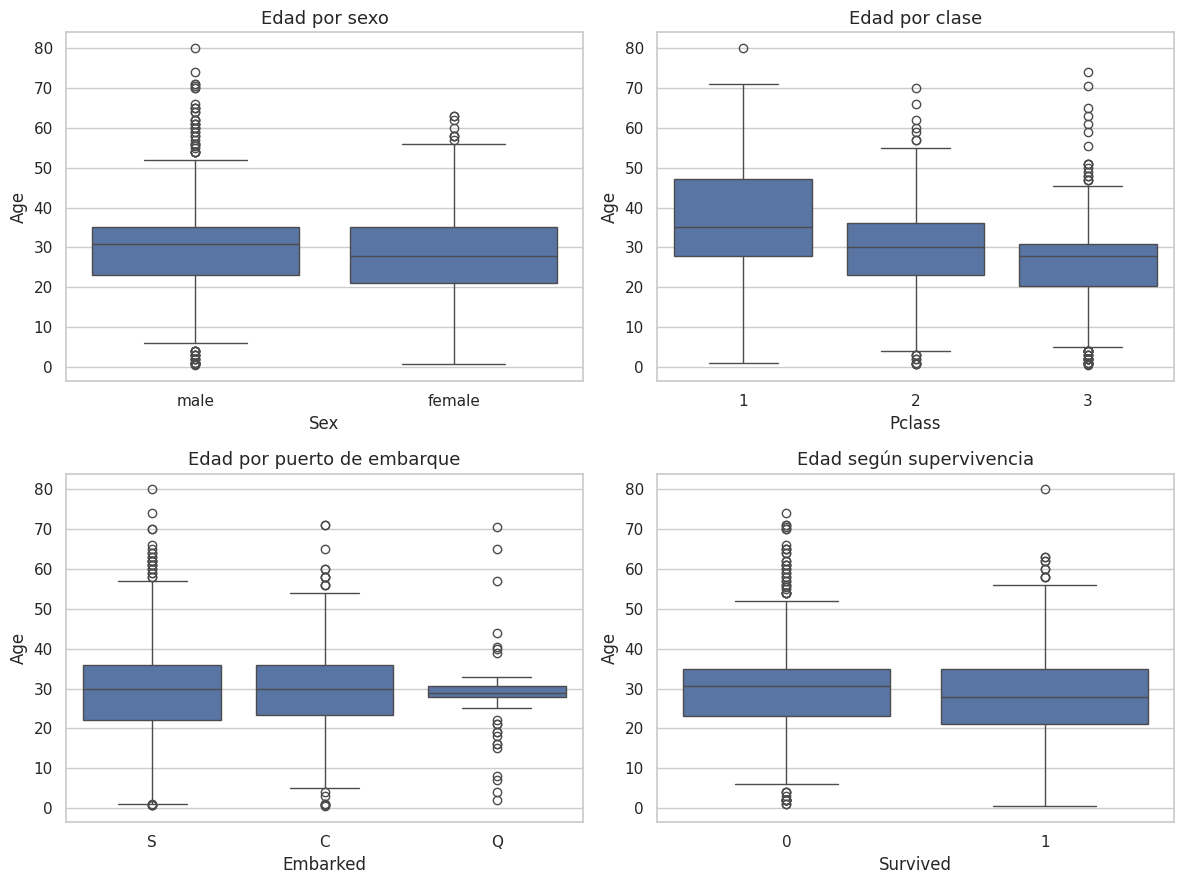

In [ ]:
# 1. fig, axes = plt.subplots(2, 2, figsize=(12, 9))
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

# 2. Dibuja sns.boxplot(data=df, x=..., y='Age', ax=axes[f, c]) para:
#      axes[0,0] -> x='Sex'     axes[0,1] -> x='Pclass'
#      axes[1,0] -> x='Embarked' axes[1,1] -> x='Survived'
sns.boxplot(data=df, x='Sex', y='Age', ax=axes[0, 0])
axes[0, 0].set_title('Edad por sexo')

sns.boxplot(data=df, x='Pclass', y='Age', ax=axes[0, 1])
axes[0, 1].set_title('Edad por clase')

sns.boxplot(data=df, x='Embarked', y='Age', ax=axes[1, 0])
axes[1, 0].set_title('Edad por puerto de embarque')

sns.boxplot(data=df, x='Survived', y='Age', ax=axes[1, 1])
axes[1, 1].set_title('Edad según supervivencia')

# 3. Cierra con plt.tight_layout(); plt.show()
plt.tight_layout()
plt.show()


### Paso 31. Distribución de la tarifa


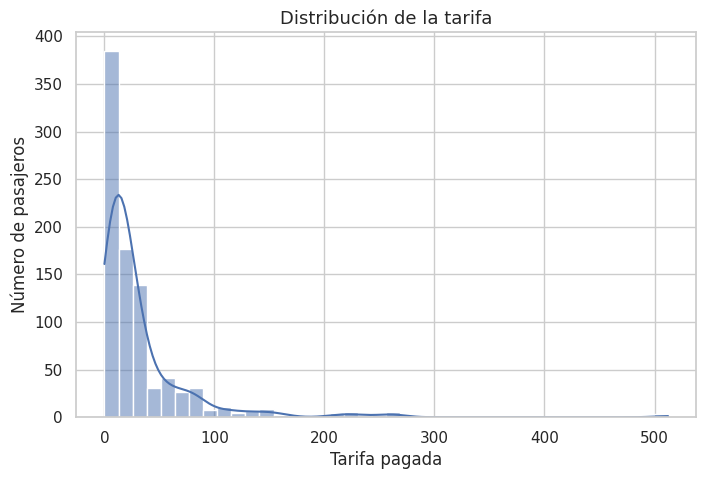

In [ ]:
# 1. Histograma con KDE: sns.histplot(df['Fare'], kde=True, bins=40)
plt.figure(figsize=(8, 5))
sns.histplot(df['Fare'], kde=True, bins=40)
plt.title('Distribución de la tarifa')
plt.xlabel('Tarifa pagada')
plt.ylabel('Número de pasajeros')
plt.show()

In [ ]:
# 2. Calcula media, mediana y asimetría (skew) de 'Fare'.
print(f"Media:    {df['Fare'].mean():.2f}")
print(f"Mediana:  {df['Fare'].median():.2f}")
print(f"Asimetría (skew): {df['Fare'].skew():.2f}")

Media:    32.20
Mediana:  14.45
Asimetría (skew): 4.79


### Evaluación — Parte 7


- **E7.1 (conceptual).** ¿Qué revelan los boxplots sobre la edad en distintos grupos? Atención: las edades ya están **imputadas**; ¿cómo afecta eso a lo que ves?


Los boxplots muestran que la edad varía sobre todo por clase (1ª más mayor) y casi nada por sexo, puerto o supervivencia. Como 177 edades fueron imputadas con solo dos valores cercanos a la media, las cajas se ven más compactas y las diferencias entre grupos más pequeñas de lo real. Para una lectura fiel conviene repetir los gráficos con las edades originales.

- **E7.2 (conceptual).** ¿La distribución de `Fare` es normal? ¿Qué te dice sobre la composición socioeconómica del barco? ¿Qué medida de tendencia central es más representativa?


Fare no sigue una distribución normal: es muy asimétrica a la derecha (skew ≈ 4.8, media ≈ 32 frente a mediana ≈ 14.5). Refleja un barco con mayoría de pasajeros de tarifa baja y una élite reducida de primera clase con tarifas muy altas. La mediana es la medida más representativa, porque la media se infla por los valores extremos

- **E7.3 (código).** Dibuja el histograma de `np.log1p(df['Fare'])`. ¿Qué cambió y por qué se usa esta transformación?


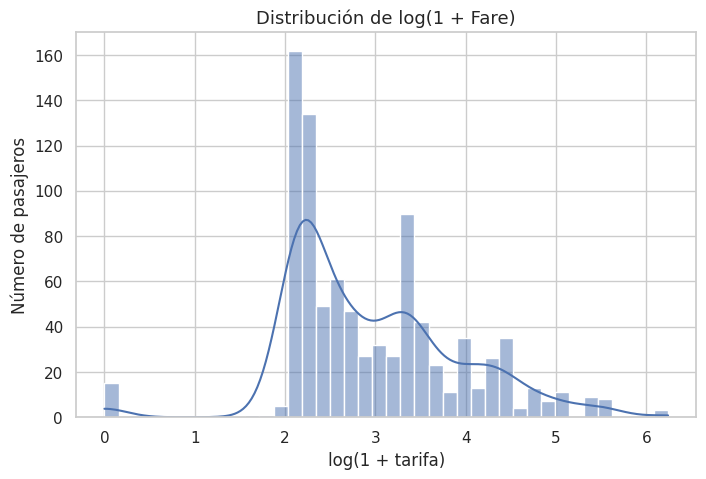

Asimetría original: 4.79
Asimetría con log1p: 0.39


In [ ]:
# Reto E7.3
plt.figure(figsize=(8, 5))
sns.histplot(np.log1p(df['Fare']), kde=True, bins=40)
plt.title('Distribución de log(1 + Fare)')
plt.xlabel('log(1 + tarifa)')
plt.ylabel('Número de pasajeros')
plt.show()

print(f"Asimetría original: {df['Fare'].skew():.2f}")
print(f"Asimetría con log1p: {np.log1p(df['Fare']).skew():.2f}")

## Parte 8 — Preparación del dataset final (Pasos 32–33)


### Paso 32. Limpieza final

**Lógica:** ya creamos versiones numéricas o derivadas de `Name`, `Sex`, `Embarked` y `Cabin`. Las originales se eliminan **en una copia**, de modo que `df` conserve todo para el análisis crítico de la Parte 9.



In [ ]:
# df_final = df.drop(columns=[...]) con las 4 columnas originales a eliminar.
df_final = df.drop(columns=['Name', 'Sex', 'Embarked', 'Cabin'])

print(df_final.shape)
print(df_final.columns.tolist())

(891, 18)
['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Person', 'Familia', 'Alone', 'Survivor', 'NEmbarked', 'NSex', 'TCabin', 'NCabin', 'TTitulo', 'NTitulo']


### Paso 33. Verificación


In [ ]:
# 1. Confirma que no quedan nulos en las variables clave (isnull().sum()).
print(df_final.isnull().sum())
print(f"Total de nulos: {df_final.isnull().sum().sum()}")

PassengerId    0
Survived       0
Pclass         0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Person         0
Familia        0
Alone          0
Survivor       0
NEmbarked      0
NSex           0
TCabin         0
NCabin         0
TTitulo        0
NTitulo        0
dtype: int64
Total de nulos: 0


In [ ]:
# 2. Revisa los tipos de datos (dtypes) e info().
print(df_final.dtypes)
df_final.info()

PassengerId      int64
Survived         int64
Pclass           int64
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Person          object
Familia          int64
Alone           object
Survivor        object
NEmbarked        int64
NSex             int64
TCabin          object
NCabin           int64
TTitulo         object
NTitulo          int64
dtype: object
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 18 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Age          891 non-null    float64
 4   SibSp        891 non-null    int64  
 5   Parch        891 non-null    int64  
 6   Ticket       891 non-null    object 
 7   Fare         891 non-null    float64
 8   Person       891 non-null    object 
 9   

In [ ]:
# 3. Genera un resumen final con describe().
print(df_final.describe().round(2))

       PassengerId  Survived  Pclass     Age   SibSp   Parch    Fare  Familia  \
count       891.00    891.00  891.00  891.00  891.00  891.00  891.00   891.00   
mean        446.00      0.38    2.31   29.74    0.52    0.38   32.20     0.90   
std         257.35      0.49    0.84   13.01    1.10    0.81   49.69     1.61   
min           1.00      0.00    1.00    0.42    0.00    0.00    0.00     0.00   
25%         223.50      0.00    2.00   22.00    0.00    0.00    7.91     0.00   
50%         446.00      0.00    3.00   30.00    0.00    0.00   14.45     0.00   
75%         668.50      1.00    3.00   35.00    1.00    0.00   31.00     1.00   
max         891.00      1.00    3.00   80.00    8.00    6.00  512.33    10.00   

       NEmbarked    NSex  NCabin  NTitulo  
count     891.00  891.00  891.00   891.00  
mean        0.36    0.65    6.72     0.63  
std         0.64    0.48    2.46     0.89  
min         0.00    0.00    0.00     0.00  
25%         0.00    0.00    8.00     0.00  
50%   

### Evaluación — Parte 8


- **E8.1 (conceptual).** ¿Qué columnas de texto siguen presentes en `df_final`? ¿Podría un modelo de Scikit-Learn usarlas tal cual?


En df_final siguen presentes las columnas de texto Ticket, TCabin, TTitulo, Person, Alone y Survivor. Un modelo de scikit-learn no puede usarlas tal cual, porque exige entradas numéricas. Hay que eliminar las redundantes o sin valor predictivo (Survivor, que causaría fuga de información, y Ticket) y codificar las demás, preferiblemente con one-hot encoding.

- **E8.2 (código).** Convierte `Alone` en una columna numérica `NAlone` (0 = con familia, 1 = solo) y `Person` en `NPerson` (child = 0, female = 1, male = 2).


In [ ]:
# Reto E8.2
df['NAlone'] = df['Alone'].map({'with Family': 0, 'Alone': 1})
df['NPerson'] = df['Person'].map({'child': 0, 'female': 1, 'male': 2})

print(df['NAlone'].value_counts().sort_index())
print(df['NPerson'].value_counts().sort_index())
print(df[['NAlone', 'NPerson']].isnull().sum())

NAlone
0    354
1    537
Name: count, dtype: int64
NPerson
0     83
1    271
2    537
Name: count, dtype: int64
NAlone     0
NPerson    0
dtype: int64


- **E8.3 (conceptual).** ¿Tiene sentido conservar `PassengerId` y `Ticket` para predecir supervivencia? Justifica.


No tiene sentido conservar PassengerId ni Ticket como predictoras. PassengerId es un número de fila sin significado y Ticket es casi único por pasajero (681 valores en 891), así que el modelo memorizaría casos en lugar de aprender patrones y no generalizaría. Su información relevante ya está en Pclass, Fare y Familia. Solo Ticket podría aprovecharse para derivar variables, como el tamaño del grupo que comparte tiquete

## Parte 9 — Análisis crítico: interacciones, asociaciones y atípicos (Pasos 34–38)

Esta es la parte donde pasas de **describir** a **argumentar**. Aquí un número solo no basta: hay que preguntarse si es *grande*, si es *confiable* (¿cuántos pasajeros hay detrás?) y si es *justo* compararlo (¿hay una tercera variable que confunde?).

> **Teoría — variable de confusión.** Si el puerto parece influir en la supervivencia, quizá lo que influye es la **clase** (cada puerto trae pasajeros de clases distintas). Para separar efectos se **estratifica**: se compara dentro de cada nivel de la tercera variable.



### Paso 34. Interacciones: clase × género


In [ ]:
# Tabla de tasa de supervivencia con Pclass en filas y Sex en columnas:
# df.pivot_table(values='Survived', index='Pclass', columns='Sex', aggfunc='mean')
tabla_cs = df.pivot_table(values='Survived', index='Pclass', columns='Sex', aggfunc='mean')
print(tabla_cs.round(3))

Sex     female   male
Pclass               
1        0.968  0.369
2        0.921  0.157
3        0.500  0.135


### Paso 35. Puerto de embarque y supervivencia (¿con confusión?)


In [ ]:
# 1. Tasa de supervivencia y número de pasajeros por 'Embarked' (groupby + agg ['mean', 'count']).
print(df.groupby('Embarked')['Survived'].agg(['mean', 'count']).round(3))

           mean  count
Embarked              
C         0.554    168
Q         0.390     77
S         0.339    646


In [ ]:
# 2. Repite estratificando por clase: pivot_table con index='Embarked', columns='Pclass'.
tabla_ep = df.pivot_table(values='Survived', index='Embarked', columns='Pclass', aggfunc='mean')
print(tabla_ep.round(2))

Pclass       1     2     3
Embarked                  
C         0.69  0.53  0.38
Q         0.50  0.67  0.38
S         0.59  0.46  0.19


### Paso 36. Tarifa y supervivencia dentro de cada clase

**Lógica:** para ver si pagar más ayudaba **dentro de una misma clase**, dividimos la tarifa en cuartiles *por clase* con `pd.qcut` y comparamos tasas.


In [ ]:
# 1. Crea df['FareQ'] con cuartiles de Fare calculados dentro de cada Pclass:
#    df['FareQ'] = df.groupby('Pclass')['Fare'].transform(lambda s: pd.qcut(s, 4, labels=False, duplicates='drop'))
df['FareQ'] = df.groupby('Pclass')['Fare'].transform(
    lambda s: pd.qcut(s, 4, labels=False, duplicates='drop')
)
print(df['FareQ'].value_counts().sort_index())
print(df.groupby('Pclass')['FareQ'].value_counts().sort_index())

FareQ
0    266
1    207
2    206
3    212
Name: count, dtype: int64
Pclass  FareQ
1       0         54
        1         54
        2         55
        3         53
2       0         84
        1          8
        2         53
        3         39
3       0        128
        1        145
        2         98
        3        120
Name: count, dtype: int64


In [ ]:
# 2. pivot_table: tasa de 'Survived' con index='FareQ' y columns='Pclass'.
print(df.pivot_table(values='Survived', index='FareQ', columns='Pclass',
                     aggfunc=['mean', 'count']).round(2))

        mean             count         
Pclass     1     2     3     1   2    3
FareQ                                  
0       0.46  0.35  0.23    54  84  128
1       0.57  0.50  0.20    54   8  145
2       0.75  0.58  0.28    55  53   98
3       0.74  0.59  0.28    53  39  120


### Paso 37. Tamaño de la familia


In [ ]:
# 1. Tasa de supervivencia y cantidad de pasajeros por 'Familia' (groupby + agg).
print(df.groupby('Familia')['Survived'].agg(['mean', 'count']).round(3))

          mean  count
Familia              
0        0.304    537
1        0.553    161
2        0.578    102
3        0.724     29
4        0.200     15
5        0.136     22
6        0.333     12
7        0.000      6
10       0.000      7


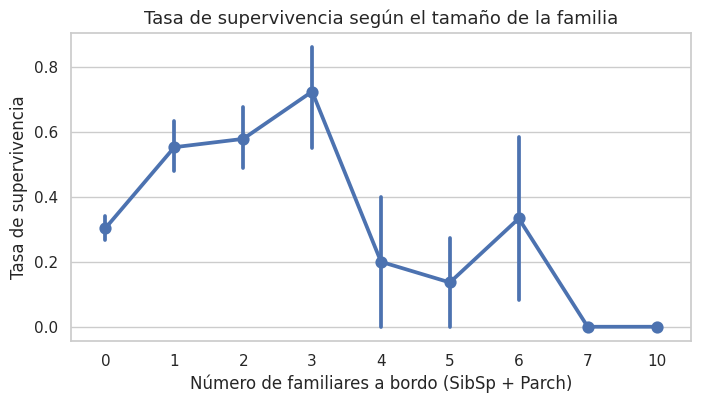

In [ ]:
# 2. Grafica con sns.pointplot(data=df, x='Familia', y='Survived').
plt.figure(figsize=(8, 4))
sns.pointplot(data=df, x='Familia', y='Survived')
plt.title('Tasa de supervivencia según el tamaño de la familia')
plt.xlabel('Número de familiares a bordo (SibSp + Parch)')
plt.ylabel('Tasa de supervivencia')
plt.show()

### Paso 38. Pasajeros atípicos

> **Teoría — regla IQR.** `IQR = Q3 − Q1`. Es atípico lo que queda fuera de `[Q1 − 1.5·IQR, Q3 + 1.5·IQR]`. *Atípico no significa erróneo:* antes de eliminar, pregunta si es un error de captura o un caso real.



In [ ]:
# 1. Escribe una función outliers_iqr(serie) que devuelva una máscara booleana
#    (usa serie.quantile([0.25, 0.75])).
def outliers_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    limite_inf = q1 - 1.5 * iqr
    limite_sup = q3 + 1.5 * iqr
    return (serie < limite_inf) | (serie > limite_sup)

In [ ]:
# 2. Aplícala a 'Fare', 'Age' y 'Familia' y cuenta cuántos atípicos hay en cada una.
for col in ['Fare', 'Age', 'Familia']:
    mascara = outliers_iqr(df[col])
    print(f"{col:8s} atípicos: {mascara.sum():3d} ({mascara.mean() * 100:.1f} %)")

Fare     atípicos: 116 (13.0 %)
Age      atípicos:  66 (7.4 %)
Familia  atípicos:  91 (10.2 %)


In [ ]:
# 3. Compara la tasa de supervivencia de los atípicos de 'Fare' contra el resto.
atipico_fare = outliers_iqr(df['Fare'])
print(df.groupby(atipico_fare)['Survived'].agg(['mean', 'count']).round(3))

        mean  count
Fare               
False  0.339    775
True   0.681    116


In [ ]:
# 4. Muestra los pasajeros con la tarifa más alta (nlargest).
print(df.nlargest(10, 'Fare')[['Name', 'Pclass', 'Fare', 'Survived', 'Embarked', 'TCabin']])

                                      Name  Pclass      Fare  Survived  \
258                       Ward, Miss. Anna       1  512.3292         1   
679     Cardeza, Mr. Thomas Drake Martinez       1  512.3292         1   
737                 Lesurer, Mr. Gustave J       1  512.3292         1   
27          Fortune, Mr. Charles Alexander       1  263.0000         0   
88              Fortune, Miss. Mabel Helen       1  263.0000         1   
341         Fortune, Miss. Alice Elizabeth       1  263.0000         1   
438                      Fortune, Mr. Mark       1  263.0000         0   
311             Ryerson, Miss. Emily Borie       1  262.3750         1   
742  Ryerson, Miss. Susan Parker "Suzette"       1  262.3750         1   
118               Baxter, Mr. Quigg Edmond       1  247.5208         0   

    Embarked TCabin  
258        C      X  
679        C      B  
737        C      B  
27         S      C  
88         S      C  
341        S      C  
438        S      C  
311      

### Evaluación — Parte 9


- **E9.1 (conceptual).** ¿Era ser mujer de tercera clase muy diferente de ser mujer de primera clase? Cuantifica la diferencia con tu tabla del Paso 34.


Sí, fue muy diferente: las mujeres de primera clase sobrevivieron ≈ 97 % y las de tercera ≈ 50 %, una brecha de ≈ 47 puntos. Esto muestra que la prioridad ‘mujeres primero’ no se aplicó igual en todas las clases: la clase tuvo un efecto propio incluso dentro del mismo sexo.

- **E9.2 (conceptual).** ¿Los puertos tienen tasas de supervivencia distintas? Tras estratificar por clase, ¿esa diferencia se mantiene? ¿Qué es entonces el puerto: causa o proxy?


Sí, el puerto muestra tasas distintas (C ≈ 55 %, Q ≈ 39 %, S ≈ 34 %), pero al estratificar por clase la diferencia se reduce mucho y solo persiste en tercera clase (≈ 38 % en C y Q frente a ≈ 19 % en S). El puerto es un proxy de la clase, y probablemente del sexo y la compañía de viaje, no una causa: no tiene efecto propio relevante una vez controlada la clase

- **E9.3 (conceptual).** ¿Existe una relación no lineal entre tarifa y supervivencia dentro de cada clase? ¿Qué cuidado hay con el tamaño de cada celda?


Dentro de cada clase la relación entre tarifa y supervivencia es débil y no lineal: solo en primera clase el cuartil más caro sobrevive claramente más (≈ 0.78 frente a ≈ 0.52), mientras que en tercera es casi plana. Como las celdas son pequeñas (≈ 45-55 pasajeros en 1ª y 2ª), las tasas son inestables, por lo que hay que reportar el tamaño de cada celda y no sobreinterpretar diferencias pequeñas

- **E9.4 (conceptual).** ¿Hay un número "óptimo" de familiares? ¿Viajar con muchos fue contraproducente? ¿Cuántos pasajeros respaldan los extremos?


La supervivencia sigue una U invertida: los que viajaban solos sobrevivieron ≈ 30 %, el máximo está en 1 a 3 familiares (≈ 55 a 72 %) y con 4 o más cae a ≈ 0-33 %. Viajar con muchos parece contraproducente, pero está confundido con la clase y se apoya en pocos casos (6 a 22 pasajeros por grupo), por lo que no hay un número ‘óptimo’ firme; solo una zona favorable de 1 a 3 familiares

- **E9.5 (código).** Verifica tu hipótesis de E3.5 con una **prueba chi-cuadrado** entre `Alone` y `Survived`. ¿Qué advertencia harías antes de concluir que "viajar con familia ayuda"? (Pista: ¿la gente sola es distinta en edad, sexo o clase?)


In [ ]:
# Retos E9.5
tabla_alone = pd.crosstab(df['Alone'], df['Survived'])
print(tabla_alone)

chi2, p, gl, esperados = stats.chi2_contingency(tabla_alone)
print(f"chi2 = {chi2:.2f}")
print(f"grados de libertad = {gl}")
print(f"p-valor = {p:.2e}")

v_cramer = np.sqrt(chi2 / (tabla_alone.values.sum() * (min(tabla_alone.shape) - 1)))
print(f"V de Cramér = {v_cramer:.2f}")

Survived       0    1
Alone                
Alone        374  163
with Family  175  179
chi2 = 36.00
grados de libertad = 1
p-valor = 1.97e-09
V de Cramér = 0.20


- **E9.6 (conceptual).** ¿Es correcto eliminar automáticamente a los outliers de `Fare`? Da un argumento a favor y uno en contra, citando cómo les fue a esos pasajeros.


No es correcto eliminarlos automáticamente. A favor: unos pocos billetes extremos (≈ 512) inflan la media y el sesgo y distorsionan modelos lineales. En contra: son casos reales, casi todos de primera clase, que sobrevivieron ≈ 73 % frente a ≈ 33 % del resto; quitarlos eliminaría información clave sobre el efecto de la clase y sesgaría las conclusiones. Es preferible conservarlos y transformar la variable con log1p



## Conclusión y reporte

Responde, **con evidencia de tu análisis** (indica el **Paso** del que proviene cada afirmación) y en un máximo de **8 líneas en total**, sin código:


1. ¿Cuál fue el factor más determinante para la supervivencia?


el sexo. Las mujeres sobrevivieron ≈ 74 % frente a ≈ 19 % de los hombres, una brecha de ≈ 55 puntos (Paso 28), con χ² ≈ 260 y V ≈ 0.54 (Paso 29) y la correlación más fuerte (≈ -0.54, Paso 27).


2. ¿Se confirma "mujeres y niños primero"? ¿Con qué excepciones?


se confirma en general: mujeres ≈ 97 %, 90 % y 50 % según la clase, frente a hombres ≈ 35 %, 7 % y 12 % (Paso 18). Excepciones: las mujeres y los niños de tercera clase sobrevivieron mucho menos (niños ≈ 37 %, por debajo de las mujeres de su clase), los niños de primera clase son solo ≈ 4 y su tasa no es fiable (Paso 18), y los hombres de primera (≈ 37 %) superaron a los de otras clases (Paso 34)

3. ¿Cómo influyó la clase social?


la supervivencia baja de ≈ 63 % en 1ª a ≈ 47 % en 2ª y ≈ 24 % en 3ª (Paso 28), con V ≈ 0.34 (E6.3). El efecto es propio, porque persiste dentro de cada sexo: mujeres ≈ 97 % frente a ≈ 50 % (Paso 34). Puerto y tarifa eran en gran parte clase disfrazada (Pasos 35-36)

4. ¿Viajar con familia ayudó o perjudicó?


ayudó con matices. Con familia ≈ 51 % frente a ≈ 30 % solos (Pasos 28-29), pero con forma de U invertida: 1 a 3 familiares ≈ 55-72 % y 4 o más ≈ 0-33 %, con pocos casos (Paso 37). Está confundido con sexo, edad y clase, así que no prueba causalidad

5. ¿Qué factores inesperados descubriste?


La edad casi no correlaciona con la supervivencia (≈ -0.07, Paso 27), pese a “niños primero”: el efecto es opuesto según el sexo y se anula en el promedio (Paso 19).
Los hombres de 2ª clase (≈ 7 %) sobrevivieron menos que los de 3ª (≈ 12 %) (Paso 18).
La familia sigue una U invertida: 1 a 3 familiares ≈ 55-72 % y 4 o más ≈ 0-33 % (Paso 37), por eso SibSp y Parch casi no correlacionan (Paso 27).
Puerto y tarifa eran clase disfrazada: la ventaja de Cherburgo se redujo al estratificar (Paso 35) y la tarifa solo mostró efecto propio en 1ª clase (Paso 36).
Tener cabina registrada (≈ 67 % frente a ≈ 30 %) funciona como proxy de la clase y pudo reconstruirse después del hundimiento (E5.4).

Después, en un párrafo corto de **limitaciones**, reflexiona sobre:


Los datos faltantes no son aleatorios y pudieron sesgar las conclusiones. En Age (20 % de nulos, concentrados en 3ª clase y hombres), la imputación por sexo (Paso 22) dejó 177 pasajeros con solo dos valores, redujo la desviación estándar (≈ 14.5 a ≈ 13.0), atenuó la relación edad-supervivencia y ocultó niños sin edad registrada, lo que subestima el efecto de “niños primero”. En Cabin (77 % de nulos, casi todos de 3ª clase), el análisis por cubierta describe sobre todo a primera clase, y la ausencia del dato es en sí un proxy de clase (Pasos 24 y E5.4). Además, varios grupos son muy pequeños (niños de 1ª clase, familias grandes), y el dataset cubre 891 de ≈ 2.224 ocupantes, así que los resultados describen esta muestra y no a todo el barco.

- ¿Qué datos faltantes pudieron sesgar tus conclusiones (edad, cabina)?


Edad (≈ 20 % faltante): faltan sobre todo en tercera clase y entre hombres. La imputación por sexo (Paso 22) dejó 177 pasajeros con solo dos valores, redujo la desviación estándar (≈ 14.5 a ≈ 13.0) y ocultó niños sin edad registrada. Resultado: se subestima el efecto de “niños primero” y la relación edad-supervivencia parece más débil de lo real.

Cabina (≈ 77 % faltante): falta casi toda en tercera clase, así que el análisis por cubierta describe sobre todo a primera clase (Pasos 11-12). “Tener cabina” funciona como proxy de la clase (≈ 67 % frente a ≈ 30 %, E5.4) y pudo registrarse después del hundimiento.

- ¿Qué variables adicionales hubieras querido tener (ubicación en el barco, tiempo de acceso a botes salvavidas, nacionalidad, tripulación)?


Habría querido tener la ubicación exacta de cada cabina, el tiempo de acceso a los botes, la nacionalidad, la condición de tripulante y las edades completas. Con ellas se podría separar el efecto de la clase del de la ubicación, comprobar las barreras de idioma y evitar el sesgo de imputación; sin ellas, las explicaciones sobre por qué la tercera clase sobrevivió menos siguen siendo hipótesis.

- ¿Qué supuestos hiciste que podrían ser cuestionables (promedio por género, `Master → Mr`, códigos numéricos arbitrarios, tratar la muestra como "todo el barco")?


Cuatro supuestos son cuestionables: imputar la edad por género ignora la clase y oculta niños; fusionar Master con Mr borra la señal de edad; codificar categorías nominales con números arbitrarios hace que las correlaciones dependan del analista; y tratar la muestra como todo el barco ignora a la tripulación y a los pasajeros ausentes. Por eso las conclusiones sobre sexo y clase son sólidas, pero las de edad, cabina y tasas globales deben leerse con cautela.